<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QSVM_IntrusionDetection_Khan2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hybrid quantum-kernel SVM for network intrusion detection: Khan et al. (2026) step by step

**Paper.** M. R. Khan, M. Z. Alam, M. Ahmad, M. Iftikhar, M. A. Khan, *"Hybrid Quantum Kernel Support Vector Machine for Network Intrusion Detection Using NISQ-Compatible Quantum Circuits"*, **Advanced Quantum Technologies 9 (10), e70481 (2026)**, DOI [10.1002/qute.70481](https://doi.org/10.1002/qute.70481).

**What this notebook does.** It rebuilds the paper's pipeline from the text: network-flow data, min-max scaling, PCA to 6 components, a 6-qubit angle-encoding circuit (`RY(pi z_i)` on every qubit followed by a chain of `CZ` gates), the fidelity kernel `K(x, y) = |<psi(x)|psi(y)>|^2`, and a classical SVM that is trained on the precomputed kernel matrix. It then trains the paper's three classical baselines (linear SVM, RBF-SVM, Random Forest with 200 trees) on exactly the same 6 numbers per flow, and compares everything with the paper's Tables 4 to 6. On top of that it
* checks the quantum kernel three ways (Qiskit `FidelityStatevectorKernel`, a by-hand `Statevector` calculation and a fast NumPy implementation of the same circuit) and the `QSVC` class against `SVC(kernel="precomputed")`;
* **proves, and shows with a numerical test, a property of the paper's circuit that the paper does not discuss**: the `CZ` chain sits *after* all the rotations, so it cancels in `|<psi(x)|psi(y)>|^2` and the kernel is a plain product of cosines (Section 5). The "entanglement layer" does nothing in this kernel;
* runs the NISQ noise study with the noise models of an IBM fake backend (`qiskit_ibm_runtime.fake_provider`), as the paper's "noise-aware simulation" contribution suggests (the paper gives no noise numbers).

**How to run.** Google Colab, a *CPU* runtime is enough: *Runtime > Run all*. The first cell installs pinned versions (a session restart may be requested; if so, run all again). `FAST_MODE = True` (default) is a class demo that finishes in about 10 minutes; `FAST_MODE = False` is the larger run documented in the configuration cell. All data are downloaded inside the notebook from public Hugging Face mirrors (no token is needed; if you have one, put it in Colab *Secrets* as `HF_TOKEN`).

**What you get at the end.** A table of the paper's numbers next to this notebook's numbers with a verdict per claim, the real class structure of both datasets, the drawn circuits, a noise study, and an honest discussion of what the paper does and does not show.

## The paper in one page

* **Problem.** Network intrusion detection (benign vs malicious flows) on modern flow datasets, with a quantum-kernel SVM sized for today's noisy (NISQ) devices.
* **Decision.** Binary: benign (+1) or malicious (-1) in the paper's notation (Eq. 1). This notebook uses *attack = 1* as the positive class, so "anomaly detection rate" is the recall of the attack class.
* **Data (Section 5.1).** **CIC-IDS2017** (the Kaggle copy; the paper says 118,149 records, seven groups including benign, 78 numeric columns) and **CICIoT2023** (47 numeric flow features; benign, DoS, DDoS, reconnaissance, brute force, spoofing, Mirai). Only the Kaggle CIC-IDS2017 link is given in the data statement.
* **Preprocessing (Algorithm 1, Section 5.2).** Drop rows with missing cells, encode categories, drop constant columns, min-max scale to [0, 1], PCA to the smallest number of components that keeps at least 95 % of the variance (the paper reports that this is 6), one qubit per component.
* **Quantum part (Eqs. 17 to 22, Algorithms 2 to 4).** `U(z) = [CZ(1,2) CZ(2,3) ... CZ(5,6)] [RY(pi z_1) ... RY(pi z_6)]` on `|0>^6`; kernel `K = |<psi(z_i)|psi(z_j)>|^2`; classical SVM on the precomputed `K`, with `C` in {0.1, 1, 10} chosen by 3-fold cross-validation. Simulation with Qiskit Aer; no real hardware.
* **Protocol (Section 5.5).** Stratified 70/30 split, a fixed seed, a single partition, no repeated runs (the paper itself says the differences are not statistically significant).
* **Baselines (Section 5.6).** Linear SVM, RBF-SVM, Random Forest (200 trees, unlimited depth, balanced class weights).
* **Claims checked here.** Table 4 (CIC-IDS2017): test accuracy 0.981, F1 0.98, anomaly detection rate 0.976 for the quantum kernel versus 0.934 / 0.954 / 0.957 for linear SVM / RBF-SVM / Random Forest. Table 5 (CICIoT2023): 0.970 / 0.984 / 0.969 for the quantum kernel, Random Forest best with 0.985 / 0.992 / 0.995. Table 6: training time, the quantum kernel the most expensive. Abstract: PCA keeps more than 95 % of the variance with 6 components.

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| CIC-IDS2017 source and size | Kaggle copy, 118,149 records, 7 groups, 78 columns | The same flow files (Hugging Face mirror `c01dsnap/CIC-IDS2017`, 2.83 M flows, 8 attack groups after merging labels into families), class-balanced sample of `N_TOTAL` flows. The paper does not say how its 118,149 records were drawn. |
| CICIoT2023 source and size | 47 features, size not stated | Hugging Face mirror `lacg030175/CIC-IoT-2023` (39 numeric features, 1.07 M training rows, 85 % attack), three samples of `N_TOTAL` flows: with the mirror's class proportions, with the *original* data set's proportions (97.6 % attack, a conjecture: the paper's F1 above its accuracy suggests an attack-dominated test set) and class-balanced. |
| Positive class and F1 | not stated (F1 may be weighted) | attack = positive; binary F1 of the attack class is the headline, weighted F1 is also printed |
| Order of scaling and PCA | min-max, then PCA; the angle needs [0, 1] | min-max -> PCA(6) -> a second min-max fitted on the training split, test values clipped to [0, 1] (`# CHOICE`) |
| Number of PCA components | 6 (reported to keep >= 95 % of the variance) | 6; the variance really retained is printed and checked as a claim |
| Kernel scale | angle `phi = pi z` | `phi = s pi z`; `s = 1` is the paper-literal model, `s` is also tuned on a validation split of the training data (`# CHOICE`, bandwidth) |
| SVM `C` | {0.1, 1, 10}, 3-fold CV | same grid, 3-fold stratified CV on the training split |
| Linear SVM | not specified | `LinearSVC(dual=False)` (same hyperplane family, much faster than libsvm's linear kernel) |
| RBF-SVM | `gamma` not stated | `gamma="scale"`, `C` from the same grid |
| Random Forest | 200 trees, unlimited depth, balanced weights | the same; `random_state = SEED` |
| Shots | not stated | exact statevector kernel for all main results; shot noise and device noise only in the noise study (1024 shots) |
| Seeds | one, unspecified | `SEED = 42`; `FAST_MODE=False` repeats over several seeds (mean +/- std) |
| Hardware | none ("simulation only") | none; an optional IBM cell runs only if `IBM_TOKEN` is set |
| Qiskit versions | Qiskit 0.43.2, Aer 0.13.2 | Qiskit 2.5.2, Aer 0.17.2, qiskit-machine-learning 0.9.1 (function-style circuits) |

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn and matplotlib.
# The pip line runs on Colab (or wherever Qiskit machine learning is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("qiskit_machine_learning") is None:
    %pip install -q "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" "qiskit-ibm-runtime==0.50.0" pylatexenc huggingface_hub pyarrow
    print("Installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("Qiskit already present; skipping pip install.")

Qiskit already present; skipping pip install.


In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
FAST_MODE = False      # True: class demo, ~2,000 flows per experiment, one seed, about 5 minutes on a CPU (measured locally).
                      # False: ~8,000 flows per experiment, 3 seeds, larger noise study; about 35 minutes locally (the committed outputs).
SEED      = 42        # CHOICE: the paper says "a fixed random seed" without giving it
DATA_DIR  = "data_qc083"   # downloaded data are cached here (scratch folder; never commit it)
IBM_TOKEN = ""        # optional: a real-hardware cell runs only if this is set; the paper reports no hardware runs
LOCAL_CIC_DIR = None  # optional: folder with the 8 CIC-IDS2017 CSVs (e.g. the Kaggle download) to skip the Hugging Face download

N_QUBITS   = 6        # paper: 6 PCA components = 6 qubits
TEST_SIZE  = 0.30     # paper: stratified 70/30 split
C_GRID     = [0.1, 1, 10]   # paper: C in {0.1, 1, 10}
CV_FOLDS   = 3        # paper: "short 3-fold checks"
BANDWIDTHS = [0.25, 0.5, 1.0, 2.0]   # CHOICE: angle scale s in phi = s*pi*z. s = 1 is the paper-literal circuit.
VAL_FRAC   = 0.25     # share of the training split held out to choose the bandwidth
RF_TREES   = 200      # paper: 200 trees, no depth limit, balanced class weights
POOL_CAP_PER_LABEL = 12_000   # CIC-IDS2017 download: at most this many flows per original label are kept in the cached pool
CICIOT_POOL_N      = 100_000  # CICIoT2023 download: size of the proportional pool kept from the 1.07 M training rows
MIN_PER_FAMILY     = 30       # CHOICE: smallest quota of any attack family in the mirror-proportion sample
SHOTS      = 1024     # shots of the shot-noise / device-noise kernel study
EXTENSION  = True     # also run the 2-repetition entangling feature map (NOT in the paper; shows where entanglement would matter)

if FAST_MODE:
    N_TOTAL = 2_000;  SEEDS = [SEED];                N_NOISE_TRAIN, N_NOISE_TEST = 24, 16
else:
    N_TOTAL = 8_000;  SEEDS = [SEED, SEED + 1, SEED + 2]; N_NOISE_TRAIN, N_NOISE_TEST = 50, 30
print(f"FAST_MODE={FAST_MODE} | flows per experiment={N_TOTAL} | seeds={SEEDS} | noise study {N_NOISE_TRAIN} train + {N_NOISE_TEST} test flows")

FAST_MODE=False | flows per experiment=8000 | seeds=[42, 43, 44] | noise study 50 train + 30 test flows


In [3]:
import os, re, json, time, math, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import sklearn, qiskit, qiskit_aer, qiskit_machine_learning, qiskit_ibm_runtime
from sklearn.svm import SVC, LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from qiskit_machine_learning.algorithms import QSVC
from qiskit_machine_learning.utils import algorithm_globals
warnings.filterwarnings("ignore")

algorithm_globals.random_seed = SEED
rng_global = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)

# Hugging Face token: only needed for gated datasets (the mirrors used here are public). Never paste a token into a notebook;
# in Colab put it in Settings > Secrets as HF_TOKEN.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)
print("qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__,
      "| qiskit-ibm-runtime", qiskit_ibm_runtime.__version__)

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1
qiskit 2.5.2 | qiskit-aer 0.17.2 | qiskit-machine-learning 0.9.1 | qiskit-ibm-runtime 0.50.0


## 1. Data: CIC-IDS2017 and CICIoT2023

Both datasets are large, so they are downloaded once, read in chunks, and reduced to a *pool* of flows that is cached in `DATA_DIR`. Every experiment later draws its own sample from the pool.

* **CIC-IDS2017** (the paper's Kaggle copy has the same eight daily CSV files). The files are streamed one at a time and deleted after reading. Identifier-like columns are not present in this "machine-learning" version of the files. Rows with NaN/inf are dropped (Algorithm 1, `Clean`). At most 12,000 flows per original label are kept in the pool; the *original* label counts of the whole data set are recorded first.
* **CICIoT2023** (Hugging Face mirror `lacg030175/CIC-IoT-2023`, public). The mirror is a re-sampled version of the original (benign up to 200,000, each attack type up to 50,000 rows), has 39 numeric features instead of 47 and 33 attack sub-types in 7 attack groups. A proportional pool of 100,000 flows is kept.

In [4]:
def hf_get(repo_id, filename, subdir):
    """Download one file of a Hugging Face *dataset* repo into DATA_DIR/subdir (public repos need no token)."""
    from huggingface_hub import hf_hub_download
    return hf_hub_download(repo_id, filename, repo_type="dataset", local_dir=os.path.join(DATA_DIR, subdir), token=HF_TOKEN or None)

def clean_label(s):
    """Original CIC-IDS2017 labels contain a non-ASCII dash ('Web Attack <dash> XSS'); map any odd character to '-'."""
    return re.sub(r"-{2,}", "-", re.sub(r"[^\x20-\x7e]+", "-", str(s))).strip()

CIC_REPO  = "c01dsnap/CIC-IDS2017"
CIC_FILES = ["Monday-WorkingHours.pcap_ISCX.csv", "Tuesday-WorkingHours.pcap_ISCX.csv", "Wednesday-workingHours.pcap_ISCX.csv",
             "Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv", "Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv",
             "Friday-WorkingHours-Morning.pcap_ISCX.csv", "Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv",
             "Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv"]
CIC_FAMILY = {"BENIGN": "Benign", "DoS Hulk": "DoS", "DoS GoldenEye": "DoS", "DoS slowloris": "DoS", "DoS Slowhttptest": "DoS", "Heartbleed": "DoS",
              "DDoS": "DDoS", "PortScan": "PortScan", "FTP-Patator": "BruteForce", "SSH-Patator": "BruteForce", "Bot": "Botnet",
              "Web Attack - Brute Force": "WebAttack", "Web Attack - XSS": "WebAttack", "Web Attack - Sql Injection": "WebAttack",
              "Infiltration": "Infiltration"}        # CHOICE: the paper says "seven groups"; merging the 15 labels like this gives 8 (benign + 7 attack families)

def load_cic_pool():
    pool_f, meta_f = os.path.join(DATA_DIR, "cic2017_pool.parquet"), os.path.join(DATA_DIR, "cic2017_meta.json")
    if os.path.exists(pool_f) and os.path.exists(meta_f):
        return pd.read_parquet(pool_f), json.load(open(meta_f))
    parts, raw_counts, n_rows, t0 = [], {}, 0, time.time()
    rg = np.random.default_rng(SEED)
    for f in CIC_FILES:
        local = os.path.join(LOCAL_CIC_DIR, f) if LOCAL_CIC_DIR else None
        p = local if (local and os.path.exists(local)) else hf_get(CIC_REPO, f, "hf_cic")
        for ch in pd.read_csv(p, chunksize=200_000, low_memory=False, encoding="latin-1"):
            ch.columns = [c.strip() for c in ch.columns]
            ch["Label"] = ch["Label"].map(clean_label)
            n_rows += len(ch)
            for k, v in ch["Label"].value_counts().items():
                raw_counts[k] = raw_counts.get(k, 0) + int(v)
            ch = ch.loc[:, ~ch.columns.duplicated()].replace([np.inf, -np.inf], np.nan).dropna()      # Algorithm 1: Clean
            for lab, g in ch.groupby("Label"):
                parts.append(g.sample(n=min(len(g), 4000), random_state=int(rg.integers(1 << 30))))
        if not (local and os.path.exists(local)):
            os.remove(p)                      # keep the disk small
        print(f"  {f}: done ({time.time()-t0:.0f} s)", flush=True)
    df = pd.concat(parts, ignore_index=True)
    keep = [g.sample(n=min(len(g), POOL_CAP_PER_LABEL), random_state=SEED) for _, g in df.groupby("Label")]
    df = pd.concat(keep, ignore_index=True)
    df.to_parquet(pool_f)
    meta = dict(raw_rows=n_rows, raw_label_counts=raw_counts)
    json.dump(meta, open(meta_f, "w"))
    return df, meta

CICIOT_REPO = "lacg030175/CIC-IoT-2023"
def load_ciciot_pool():
    pool_f, meta_f = os.path.join(DATA_DIR, "ciciot_pool.parquet"), os.path.join(DATA_DIR, "ciciot_meta.json")
    if os.path.exists(pool_f) and os.path.exists(meta_f):
        return pd.read_parquet(pool_f), json.load(open(meta_f))
    df = pd.read_parquet(hf_get(CICIOT_REPO, "random/train-00000-of-00001.parquet", "hf_ciciot"))
    meta = dict(raw_rows=int(len(df)), raw_label_counts={k: int(v) for k, v in df["Label"].value_counts().items()},
                raw_family_counts={k: int(v) for k, v in df["attack_class"].value_counts().items()})
    parts = [g.sample(frac=min(1.0, CICIOT_POOL_N / len(df)), random_state=SEED) for _, g in df.groupby("Label")]
    pool = pd.concat(parts, ignore_index=True)
    pool.to_parquet(pool_f); json.dump(meta, open(meta_f, "w"))
    return pool, meta

t0 = time.time()
cic_raw, cic_meta = load_cic_pool()
cic_meta["raw_label_counts"] = {clean_label(k): v for k, v in cic_meta["raw_label_counts"].items()}
cic_raw["Label"] = cic_raw["Label"].map(clean_label)
cic_raw["family"] = cic_raw["Label"].map(CIC_FAMILY)
assert cic_raw["family"].notna().all(), set(cic_raw.loc[cic_raw["family"].isna(), "Label"])
cic_raw["y"] = (cic_raw["family"] != "Benign").astype(int)
CIC_FEATURES = [c for c in cic_raw.columns if c not in ("Label", "family", "y")]

iot_raw, iot_meta = load_ciciot_pool()
iot_raw["family"] = iot_raw["attack_class"].where(iot_raw["attack_class"].str.lower() != "benign", "Benign")
iot_raw["y"] = (iot_raw["family"] != "Benign").astype(int)
assert (iot_raw["y"] == iot_raw["label"]).all()
IOT_FEATURES = [c for c in iot_raw.columns if c not in ("Label", "attack_class", "label", "family", "y")]
print(f"CIC-IDS2017 pool {cic_raw.shape} ({len(CIC_FEATURES)} features), whole data set {cic_meta['raw_rows']:,} flows | "
      f"CICIoT2023 pool {iot_raw.shape} ({len(IOT_FEATURES)} features), mirror training file {iot_meta['raw_rows']:,} rows | {time.time()-t0:.0f} s")

CIC-IDS2017 pool (63198, 81) (78 features), whole data set 2,830,743 flows | CICIoT2023 pool (100001, 44) (39 features), mirror training file 1,073,851 rows | 1 s


## 2. Labels, sampling, split and preprocessing (Algorithm 1)

* **Labels.** `y = 1` for every attack, `0` for benign. The attack *family* is kept next to it for plots and per-family analysis.
* **Sampling.** The quantum kernel needs an `N x N` matrix, so a few thousand flows are used (the paper does not say how many; its 929 s kernel time suggests a few thousand). Three modes: `balanced` (50 % benign, the attack half spread as evenly as possible over the attack families), `natural` (the pool's class proportions, at least 30 flows per family) and `original` (CICIoT2023 only: 2.4 % benign as in the 46.7 M-row original, attack families in pool proportions).
* **Split.** Stratified 70/30 on the attack family (so also on the binary label), `random_state = seed`.
* **Preprocessing, fitted on the training split only.** `VarFilter` (drop columns that are constant on the training split) -> `MinMaxScaler` -> `PCA(6)` -> a second `MinMaxScaler` to [0, 1] so that `phi = pi z` lies in [0, pi]. Test values are clipped to [0, 1] (`# CHOICE`; the paper scales before the PCA and does not say how its [0, 1] angle range is guaranteed after it).

In [5]:
def waterfill(avail, total):
    """Spread `total` items over groups as evenly as possible without exceeding each group's availability."""
    quota, remaining, active = {k: 0 for k in avail}, int(total), [k for k, v in avail.items() if v > 0]
    while remaining > 0 and active:
        share = max(1, remaining // len(active))
        for k in list(active):
            take = min(share, avail[k] - quota[k], remaining)
            quota[k] += take; remaining -= take
            if quota[k] >= avail[k]: active.remove(k)
    return quota

def draw_sample(pool, n_total, mode, seed):
    """Row positions of a sample of the pool. mode: 'balanced' (50 % benign) or 'natural' (pool proportions)."""
    rg = np.random.default_rng(seed)
    fam = pool["family"].values
    counts = pool["family"].value_counts().to_dict()
    if mode == "balanced":
        n_ben = min(n_total // 2, counts["Benign"])
        quota = waterfill({k: v for k, v in counts.items() if k != "Benign"}, n_total - n_ben)
        quota["Benign"] = n_ben
    elif mode == "original":
        n_ben = min(int(round(0.024 * n_total)), counts["Benign"])
        att = {k: v for k, v in counts.items() if k != "Benign"}; tot = sum(att.values())
        quota = {k: min(v, max(MIN_PER_FAMILY, int(round((n_total - n_ben) * v / tot)))) for k, v in att.items()}
        quota["Benign"] = n_ben
    else:
        tot = sum(counts.values())
        quota = {k: min(v, max(MIN_PER_FAMILY, int(round(n_total * v / tot)))) for k, v in counts.items()}
    idx = np.concatenate([rg.choice(np.flatnonzero(fam == k), size=q, replace=False) for k, q in quota.items() if q > 0])
    return np.sort(idx)

class Prep:
    """Algorithm 1 + Section 5.2 of the paper, fitted on the training split only.
    mode 'paper': MinMax -> PCA; mode 'standard': StandardScaler -> PCA (used only in the sensitivity check)."""
    def __init__(self, n_comp=N_QUBITS, mode="paper", seed=SEED):
        self.n_comp, self.mode, self.seed = n_comp, mode, seed
    def fit(self, X):
        X = np.asarray(X, dtype=float)
        self.keep = X.var(axis=0) > 1e-12                       # VarFilter: constant columns on the training split
        X = X[:, self.keep]
        self.s1 = (MinMaxScaler() if self.mode == "paper" else StandardScaler()).fit(X)
        self.pca = PCA(n_components=self.n_comp, random_state=self.seed).fit(self.s1.transform(X))
        self.s2 = MinMaxScaler((0.0, 1.0)).fit(self.pca.transform(self.s1.transform(X)))
        self.explained = float(self.pca.explained_variance_ratio_.sum())
        return self
    def stages(self, X):
        """(raw PCA coordinates, coordinates in [0, 1]); the second is what the circuit encodes as phi = s*pi*z."""
        P = self.pca.transform(self.s1.transform(np.asarray(X, dtype=float)[:, self.keep]))
        return P, np.clip(self.s2.transform(P), 0.0, 1.0)
    def transform(self, X): return self.stages(X)[1]
    def full(self, X):
        """All kept features, scaled (input of the 'all features' baselines)."""
        return self.s1.transform(np.asarray(X, dtype=float)[:, self.keep])

CONFIGS = {   # name -> (pool, feature list, sampling mode)
    "CIC-IDS2017 (balanced)":          (cic_raw, CIC_FEATURES, "balanced"),
    "CICIoT2023 (mirror proportions)": (iot_raw, IOT_FEATURES, "natural"),
    "CICIoT2023 (original proportions)": (iot_raw, IOT_FEATURES, "original"),
    "CICIoT2023 (balanced)":           (iot_raw, IOT_FEATURES, "balanced"),
}
_SPLITS = {}
def get_split(name, seed):
    """Sample, stratified 70/30 split, fitted preprocessing. Cached so that every later cell sees the same split."""
    key = (name, seed)
    if key not in _SPLITS:
        pool, feats, mode = CONFIGS[name]
        pos = draw_sample(pool, N_TOTAL, mode, seed)
        sub = pool.iloc[pos]
        itr, ite = train_test_split(np.arange(len(sub)), test_size=TEST_SIZE, stratify=sub["family"].values, random_state=seed)
        tr, te = sub.iloc[itr], sub.iloc[ite]
        prep = Prep(mode="paper", seed=seed).fit(tr[feats].values)
        Ptr, Atr = prep.stages(tr[feats].values); Pte, Ate = prep.stages(te[feats].values)
        _SPLITS[key] = dict(name=name, seed=seed, prep=prep, feats=feats, Xtr=tr[feats].values, Xte=te[feats].values,
                            ytr=tr["y"].values, yte=te["y"].values, ftr=tr["family"].values, fte=te["family"].values,
                            Ptr=Ptr, Atr=Atr, Pte=Pte, Ate=Ate, lab_tr=tr["Label"].values)
    return _SPLITS[key]

for name in CONFIGS:
    sp = get_split(name, SEED)
    print(f"{name:36s} train {len(sp['ytr']):5d} (attack {sp['ytr'].mean():.2f}) | test {len(sp['yte']):5d} (attack {sp['yte'].mean():.2f}) | "
          f"majority-class accuracy {max(sp['yte'].mean(), 1 - sp['yte'].mean()):.3f} | variance kept by the {N_QUBITS} PCA components: {sp['prep'].explained:.3f} | angles in [{sp['Atr'].min():.2f}, {sp['Atr'].max():.2f}] x pi")

CIC-IDS2017 (balanced)               train  5600 (attack 0.50) | test  2400 (attack 0.50) | majority-class accuracy 0.500 | variance kept by the 6 PCA components: 0.824 | angles in [0.00, 1.00] x pi
CICIoT2023 (mirror proportions)      train  5600 (attack 0.85) | test  2400 (attack 0.85) | majority-class accuracy 0.851 | variance kept by the 6 PCA components: 0.849 | angles in [0.00, 1.00] x pi


CICIoT2023 (original proportions)    train  5598 (attack 0.98) | test  2400 (attack 0.98) | majority-class accuracy 0.976 | variance kept by the 6 PCA components: 0.849 | angles in [0.00, 1.00] x pi
CICIoT2023 (balanced)                train  5600 (attack 0.50) | test  2400 (attack 0.50) | majority-class accuracy 0.500 | variance kept by the 6 PCA components: 0.831 | angles in [0.00, 1.00] x pi


## Dataset Exploration and Visualisation

This is Section 3 of the notebook. It shows, for both real data sets, what the flows look like *before* any quantum model sees them: shape, feature names, the original label values and counts, the class distribution, and a 2-D scatter of the real flows coloured by their ground-truth label. Everything below is computed from the downloaded data (no synthetic points). The attack **family** (DoS, DDoS, Recon, ...) is kept instead of collapsing to benign/attack, because the model only ever sees the binary label but the families explain why some attacks are easy and others are not.

In [6]:
VIS = ["CIC-IDS2017 (balanced)", "CICIoT2023 (mirror proportions)"]
FAMILIES = sorted(set(cic_raw["family"]) | set(iot_raw["family"]), key=lambda f: (f != "Benign", f))
ATTACK_COLORS = ["#d62728", "#1f77b4", "#2ca02c", "#ff7f0e", "#9467bd", "#8c564b", "#e377c2", "#17becf", "#bcbd22", "#000000", "#7fc97f", "#beaed4", "#fdc086"]
PALETTE = {f: "#7f7f7f" for f in FAMILIES}
PALETTE.update({f: ATTACK_COLORS[i] for i, f in enumerate([f for f in FAMILIES if f != "Benign"])})

for name, raw, meta, feats in (("CIC-IDS2017", cic_raw, cic_meta, CIC_FEATURES), ("CICIoT2023", iot_raw, iot_meta, IOT_FEATURES)):
    print("=" * 100); print(name)
    print(f"whole data set / mirror file: {meta['raw_rows']:,} flows | cached pool: shape {raw.shape} | features: {len(feats)} numeric columns")
    print("feature names:", ", ".join(feats))
    print("\noriginal label values and counts (whole data set / mirror file):")
    print(pd.Series(meta["raw_label_counts"]).sort_values(ascending=False).to_string())
    print("\nattack families used here (pool counts):"); print(raw["family"].value_counts().to_string())
    print("\nfeature summary (pool, first 6 features):"); print(raw[feats[:6]].describe().T.round(2).to_string())

CIC-IDS2017
whole data set / mirror file: 2,830,743 flows | cached pool: shape (63198, 81) | features: 78 numeric columns
feature names: Destination Port, Flow Duration, Total Fwd Packets, Total Backward Packets, Total Length of Fwd Packets, Total Length of Bwd Packets, Fwd Packet Length Max, Fwd Packet Length Min, Fwd Packet Length Mean, Fwd Packet Length Std, Bwd Packet Length Max, Bwd Packet Length Min, Bwd Packet Length Mean, Bwd Packet Length Std, Flow Bytes/s, Flow Packets/s, Flow IAT Mean, Flow IAT Std, Flow IAT Max, Flow IAT Min, Fwd IAT Total, Fwd IAT Mean, Fwd IAT Std, Fwd IAT Max, Fwd IAT Min, Bwd IAT Total, Bwd IAT Mean, Bwd IAT Std, Bwd IAT Max, Bwd IAT Min, Fwd PSH Flags, Bwd PSH Flags, Fwd URG Flags, Bwd URG Flags, Fwd Header Length, Bwd Header Length, Fwd Packets/s, Bwd Packets/s, Min Packet Length, Max Packet Length, Packet Length Mean, Packet Length Std, Packet Length Variance, FIN Flag Count, SYN Flag Count, RST Flag Count, PSH Flag Count, ACK Flag Count, URG Flag Co

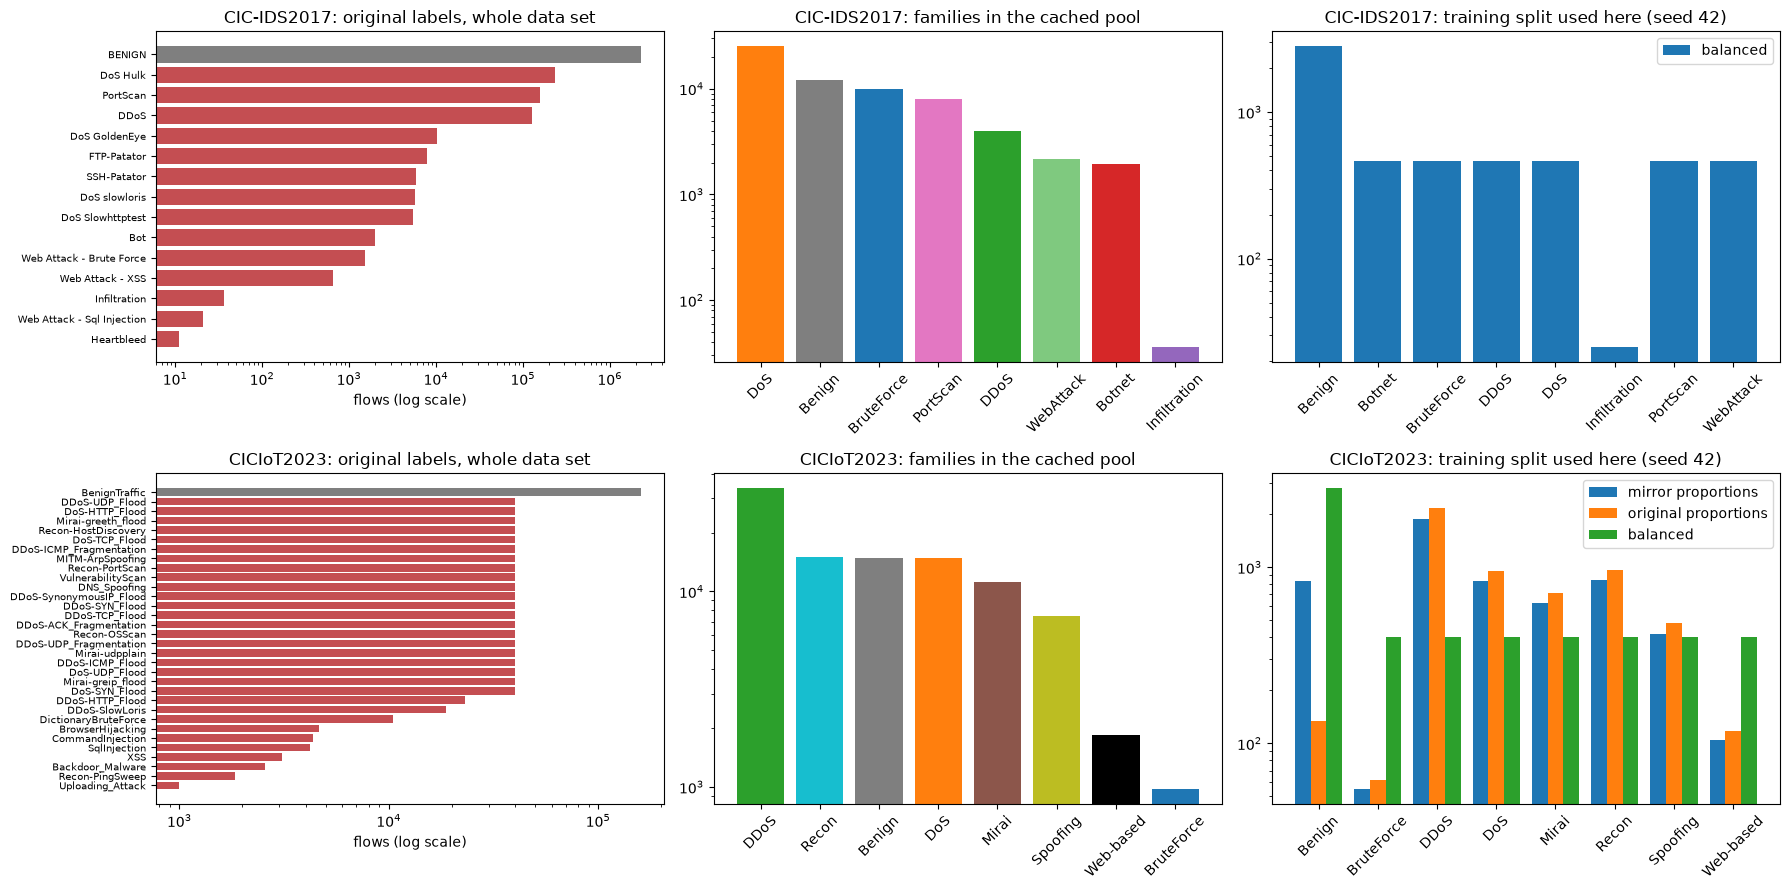

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for r, (name, raw, meta) in enumerate((("CIC-IDS2017", cic_raw, cic_meta), ("CICIoT2023", iot_raw, iot_meta))):
    lab = pd.Series(meta["raw_label_counts"]).sort_values()
    col = ["#7f7f7f" if k in ("BENIGN", "BenignTraffic") else "#c44e52" for k in lab.index]
    axes[r, 0].barh(lab.index, lab.values, color=col); axes[r, 0].set_xscale("log"); axes[r, 0].set_xlabel("flows (log scale)")
    axes[r, 0].set_title(f"{name}: original labels, whole data set"); axes[r, 0].tick_params(axis="y", labelsize=7)
    fam = raw["family"].value_counts()
    axes[r, 1].bar(fam.index, fam.values, color=[PALETTE[f] for f in fam.index]); axes[r, 1].set_yscale("log")
    axes[r, 1].set_title(f"{name}: families in the cached pool"); axes[r, 1].tick_params(axis="x", rotation=45)
    names = [n for n in CONFIGS if n.startswith(name)]
    w = 0.8 / len(names)
    for j, n in enumerate(names):
        sp = get_split(n, SEED); c = pd.Series(sp["ftr"]).value_counts().reindex(FAMILIES).dropna()
        axes[r, 2].bar(np.arange(len(c)) + j * w, c.values, w, label=n.split("(")[1].strip(")") if "(" in n else n)
        axes[r, 2].set_xticks(np.arange(len(c)) + w * (len(names) - 1) / 2); axes[r, 2].set_xticklabels(c.index, rotation=45)
    axes[r, 2].set_yscale("log"); axes[r, 2].legend(); axes[r, 2].set_title(f"{name}: training split used here (seed {SEED})")
plt.tight_layout(); plt.show()

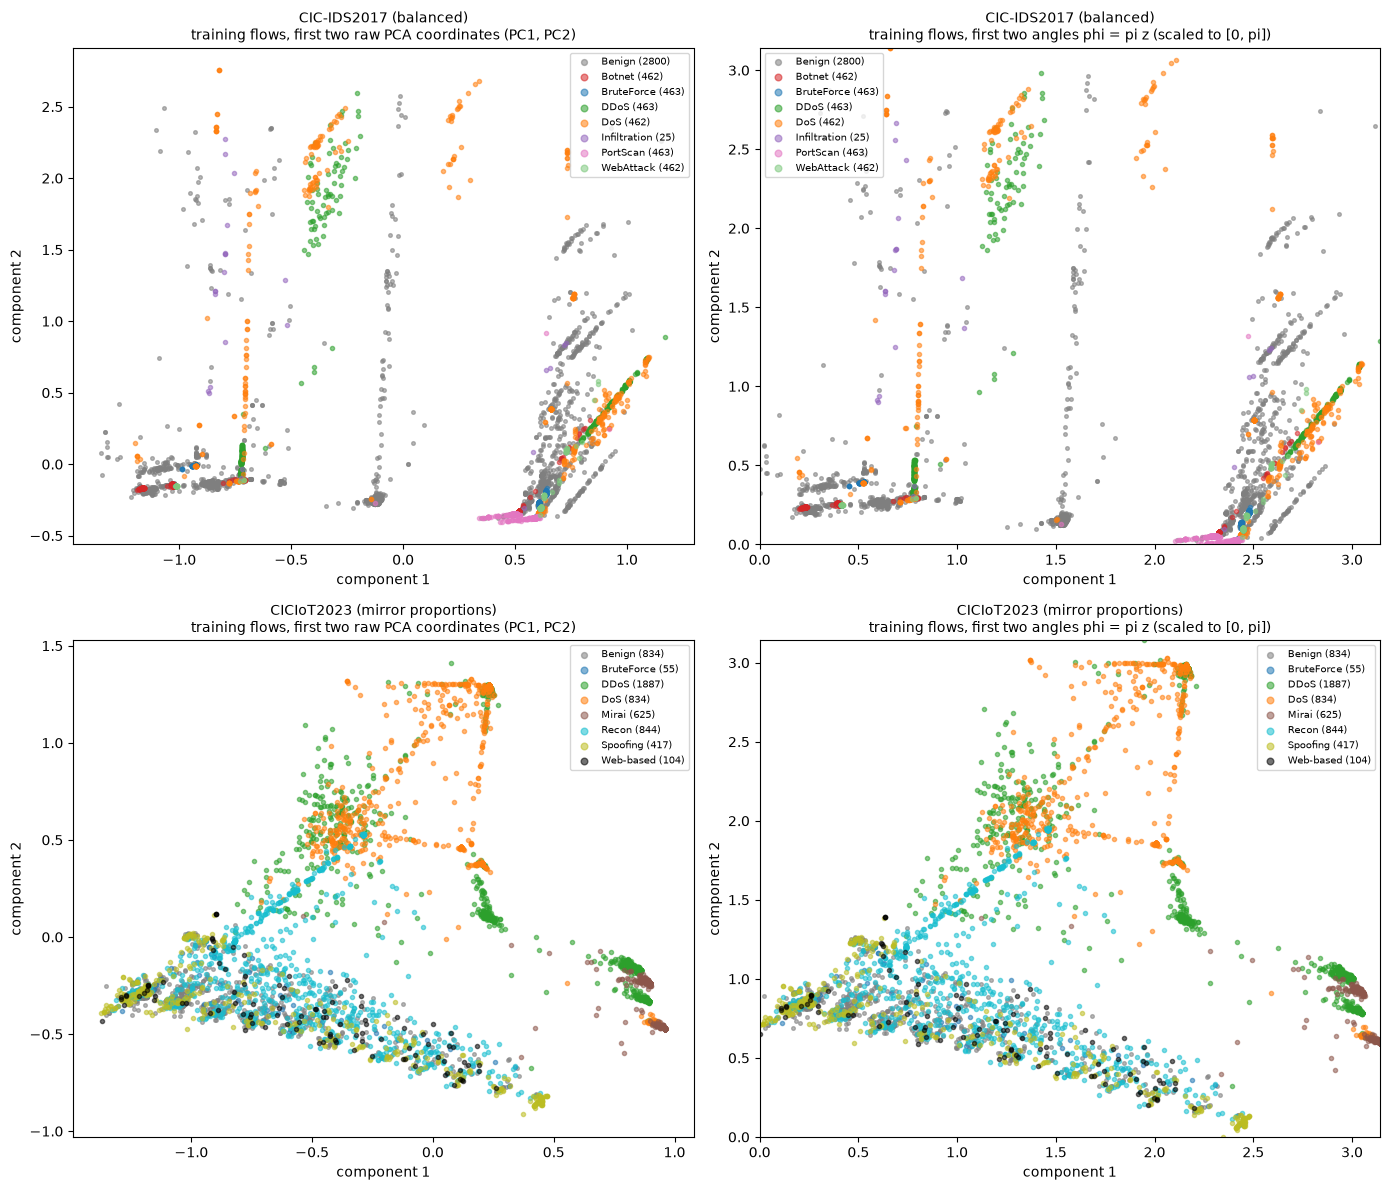

CIC-IDS2017 (balanced): 6 PCA components keep 0.824 of the variance of the (min-max scaled) features
CICIoT2023 (mirror proportions): 6 PCA components keep 0.849 of the variance of the (min-max scaled) features


In [8]:
# 2-D scatter of the REAL training flows, coloured by the ground-truth family:
# left = the first two raw PCA coordinates (PCA fitted on the training split), right = the same two coordinates after the second min-max
# scaling, i.e. the first two rotation angles phi_1 = pi z_1 and phi_2 = pi z_2 in [0, pi] that the circuit encodes.
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for r, name in enumerate(VIS):
    sp = get_split(name, SEED)
    for c, (XY, ttl, lim) in enumerate(((sp["Ptr"][:, :2], "raw PCA coordinates (PC1, PC2)", None), (np.pi * sp["Atr"][:, :2], "angles phi = pi z (scaled to [0, pi])", (0, np.pi)))):
        ax = axes[r, c]
        for f in FAMILIES:
            m = sp["ftr"] == f
            if m.any():
                ax.scatter(XY[m, 0], XY[m, 1], s=9 if f != "Benign" else 7, alpha=0.55, color=PALETTE[f], label=f"{f} ({m.sum()})", rasterized=True)
        if lim: ax.set_xlim(*lim); ax.set_ylim(*lim)
        ax.set_title(f"{name}\ntraining flows, first two {ttl}", fontsize=10); ax.set_xlabel("component 1"); ax.set_ylabel("component 2")
        ax.legend(fontsize=7, markerscale=1.6, loc="best")
plt.tight_layout(); plt.show()
for name in VIS:
    sp = get_split(name, SEED); print(f"{name}: 6 PCA components keep {sp['prep'].explained:.3f} of the variance of the (min-max scaled) features")

**What to see.** In the CIC-IDS2017 plot the benign flows (grey) sit in the same region as several attack families, and the first two components alone do not separate them; the classifier has six angles, not two, and the kernel is evaluated on all six. In CICIoT2023 the picture is much more crowded because the mirror contains 33 attack sub-types in 7 groups that overlap heavily in the first two components. Note also the share of variance the six components keep (printed above): the paper reports that six components keep more than 95 %; whether that holds here depends on the data actually drawn, and it is checked as a claim at the end.

## Quantum Circuit Architecture

The paper's quantum part is the 6-qubit circuit of Figure 4 / Eq. 21: one `RY(pi z_i)` per qubit followed by a chain `CZ(1,2) ... CZ(5,6)`, with no trainable parameters (the model is non-parametric: only the SVM is trained). Below are the circuits that are **actually executed** by Qiskit in this notebook:

1. the **feature map** `U(z)` of the paper (one repetition);
2. the **compute-uncompute kernel circuit** `U(y)^dagger U(x)` with measurement of all qubits: the probability of the outcome `000000` is exactly `|<psi(x)|psi(y)>|^2`; this is the circuit a quantum computer would run for every pair of flows, and what the noise study (Section 8) runs on the fake IBM backend;
3. the **two-repetition feature map** of the extension (not in the paper), shown because it is a distinct architecture that the notebook trains.

Assumptions where the paper is silent: the paper only says "angle encoding with `RY`" and "CZ between neighbouring qubits", so the gate order is taken from Eq. 21 (rotations first, then the CZ chain), the entanglement is linear (as Figure 4), and there are no extra Hadamards, no data re-uploading and no trainable layer. `x_i` below are the PCA/min-max coordinates in [0, 1]; the bandwidth `s` multiplies them before they enter the circuit.

1. feature map U(x) (paper, Fig. 4)            qubits= 6 | depth= 6 | data parameters= 6 | trainable parameters=0 | gates={'ry': 6, 'cz': 5}
2. kernel circuit U(y)^dagger U(x) + measure   qubits= 6 | depth=13 | data parameters=12 | trainable parameters=0 | gates={'ry': 12, 'cz': 10, 'measure': 6, 'barrier': 1}
3. two-repetition feature map (extension)      qubits= 6 | depth= 9 | data parameters= 6 | trainable parameters=0 | gates={'ry': 12, 'cz': 10}

Figure 1: feature map U(x) of the paper (executed for every flow):


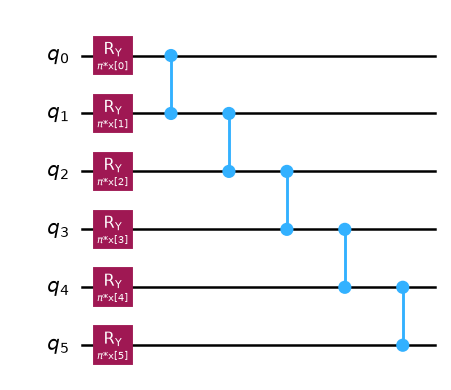

In [9]:
from IPython.display import display

def feature_map(n=N_QUBITS, reps=1, name="x"):
    """Paper's circuit (Eq. 21) for reps=1: RY(pi x_i) on every qubit, then the linear CZ chain. reps=2 repeats the block (extension)."""
    x = ParameterVector(name, n)
    qc = QuantumCircuit(n, name=f"U({name}), reps={reps}")
    for _ in range(reps):
        for i in range(n):
            qc.ry(np.pi * x[i], i)
        for i in range(n - 1):
            qc.cz(i, i + 1)
    return qc

def kernel_circuit(n=N_QUBITS, reps=1):
    """Compute-uncompute circuit U(y)^dagger U(x) followed by measurement: P(0...0) = |<psi(x)|psi(y)>|^2."""
    fx, fy = feature_map(n, reps, "x"), feature_map(n, reps, "y")
    kc = fx.compose(fy.inverse())
    kc.measure_all()
    return kc, list(fx.parameters), list(fy.parameters)

FM1, FM2 = feature_map(N_QUBITS, 1), feature_map(N_QUBITS, 2)
KC1, KC_X, KC_Y = kernel_circuit(N_QUBITS, 1)

def circuit_stats(qc, label):
    ops = dict(qc.count_ops())
    print(f"{label:46s} qubits={qc.num_qubits:2d} | depth={qc.depth():2d} | data parameters={qc.num_parameters:2d} | trainable parameters=0 | gates={ops}")

circuit_stats(FM1, "1. feature map U(x) (paper, Fig. 4)")
circuit_stats(KC1, "2. kernel circuit U(y)^dagger U(x) + measure")
circuit_stats(FM2, "3. two-repetition feature map (extension)")
print("\nFigure 1: feature map U(x) of the paper (executed for every flow):")
display(FM1.draw("mpl", fold=-1, scale=0.9))

Figure 2: compute-uncompute kernel circuit U(y)^dagger U(x) with measurement of all qubits (the circuit run per pair of flows in Section 8):


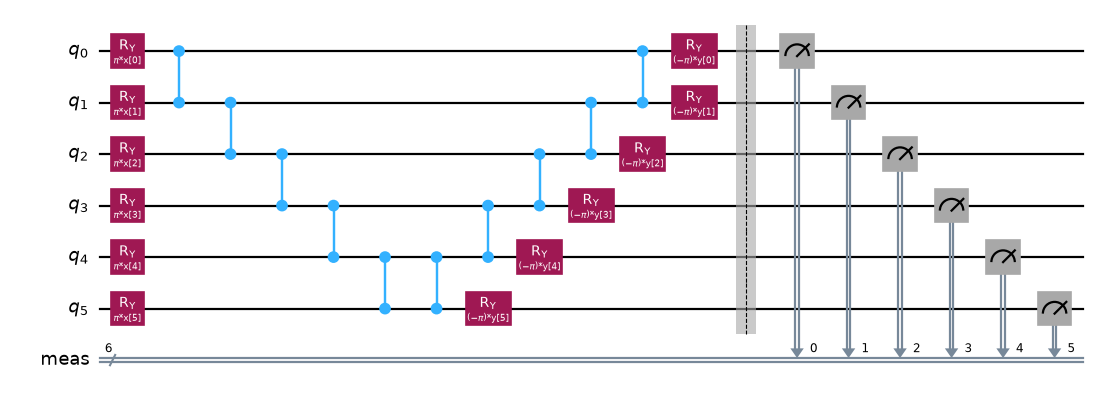


Figure 3: two-repetition feature map used by the extension row (NOT in the paper); here the CZ gates sit between rotation layers:


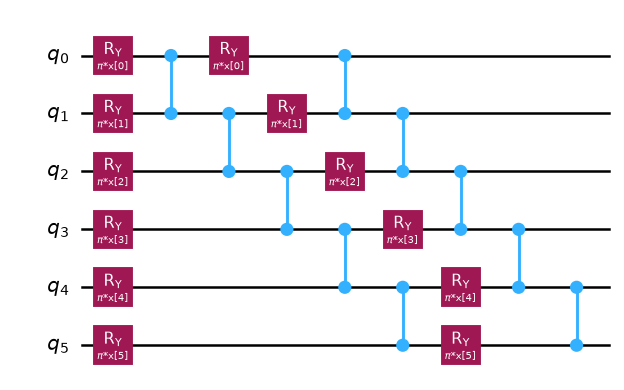

In [10]:
print("Figure 2: compute-uncompute kernel circuit U(y)^dagger U(x) with measurement of all qubits (the circuit run per pair of flows in Section 8):")
display(KC1.draw("mpl", fold=-1, scale=0.8))
print("\nFigure 3: two-repetition feature map used by the extension row (NOT in the paper); here the CZ gates sit between rotation layers:")
display(FM2.draw("mpl", fold=-1, scale=0.9))

## 5. The quantum kernel: three implementations that must agree

`K(x, y) = |<psi(x)|psi(y)>|^2` is computed by

1. **Qiskit `FidelityStatevectorKernel`** (the reference; exact statevectors, every pair evaluated one by one, about 30,000 pairs per second);
2. **by hand**: `Statevector(circuit.assign_parameters(x))` for every flow, then `|<a|b>|^2` as a matrix product;
3. **a vectorised NumPy simulation of the same gate list** (RY on one axis of a `(N, 2, ..., 2)` tensor, CZ as a sign flip). The big kernel matrices of the experiments use this one, because the Qiskit class needs about ten minutes per 4,000 x 4,000 matrix. Its output is asserted equal to (1) and (2) on a test set.

Then `QSVC(quantum_kernel=...)` is compared with `SVC(kernel="precomputed")`. The paper uses the latter ("we precomputed the kernel and then trained the SVM").

In [11]:
def states_np(Z, scale=1.0, reps=1):
    """Exact statevectors of the circuit of feature_map(reps), for every row of Z (values in [0, 1]), as a (N, 2**n) real array.
    Tensor axis i+1 is qubit i (the ordering differs from Qiskit's little-endian vector, the kernel does not depend on it)."""
    Z = np.asarray(Z, float); N, n = Z.shape
    psi = np.zeros((N,) + (2,) * n); psi[(slice(None),) + (0,) * n] = 1.0
    sign = np.ones((2,) * n)
    for i in range(n - 1):                                    # CZ(i, i+1): -1 where both qubits are |1>
        idx = [slice(None)] * n; idx[i] = 1; idx[i + 1] = 1
        sign[tuple(idx)] *= -1
    th = scale * np.pi * Z
    for _ in range(reps):
        for i in range(n):                                    # RY(theta) = [[c, -s], [s, c]]
            c = np.cos(th[:, i] / 2).reshape((N,) + (1,) * n); s = np.sin(th[:, i] / 2).reshape((N,) + (1,) * n)
            a0, a1 = np.take(psi, [0], axis=i + 1), np.take(psi, [1], axis=i + 1)
            psi = np.concatenate([c * a0 - s * a1, s * a0 + c * a1], axis=i + 1)
        psi = psi * sign
    return psi.reshape(N, -1)

def gram(PA, PB):
    return (PA @ PB.T) ** 2

rg = np.random.default_rng(SEED)
sp0 = get_split("CIC-IDS2017 (balanced)", SEED)
sel_a, sel_b = rg.choice(len(sp0["Atr"]), 40, replace=False), rg.choice(len(sp0["Atr"]), 30, replace=False)
XA, XB = sp0["Atr"][sel_a], sp0["Atr"][sel_b]
for reps, fm in ((1, FM1), (2, FM2)):
    for s in (1.0, 0.5):
        t0 = time.perf_counter()
        K_fsk = FidelityStatevectorKernel(feature_map=fm).evaluate(s * XA, s * XB)               # (1) Qiskit class
        t_fsk = time.perf_counter() - t0
        SA = np.array([Statevector(fm.assign_parameters(s * x)).data for x in XA])               # (2) by hand
        SB = np.array([Statevector(fm.assign_parameters(s * x)).data for x in XB])
        K_hand = np.abs(SA.conj() @ SB.T) ** 2
        K_np = gram(states_np(XA, s, reps), states_np(XB, s, reps))                              # (3) NumPy
        assert np.allclose(K_fsk, K_hand, atol=1e-10) and np.allclose(K_fsk, K_np, atol=1e-10), "kernel implementations disagree"
        print(f"reps={reps} s={s}: FidelityStatevectorKernel == by-hand Statevector == NumPy simulation  (max |diff| {np.abs(K_fsk-K_np).max():.1e}); "
              f"FSK {t_fsk:.1f} s for {K_fsk.size} pairs = {1e6*t_fsk/K_fsk.size:.0f} microseconds per pair")
T_FSK_PAIR = t_fsk / K_fsk.size

# QSVC with the Qiskit kernel vs SVC on the precomputed kernel
ia, ib = rg.choice(len(sp0["Atr"]), 120, replace=False), rg.choice(len(sp0["Ate"]), 60, replace=False)
Xq, yq, Xt, yt = sp0["Atr"][ia], sp0["ytr"][ia], sp0["Ate"][ib], sp0["yte"][ib]
qsvc = QSVC(quantum_kernel=FidelityStatevectorKernel(feature_map=FM1), C=1.0).fit(Xq, yq)
svc = SVC(kernel="precomputed", C=1.0).fit(gram(states_np(Xq), states_np(Xq)), yq)
p_q, p_s = qsvc.predict(Xt), svc.predict(gram(states_np(Xt), states_np(Xq)))
print(f"QSVC vs SVC(precomputed): identical predictions on {len(Xt)} test flows: {np.array_equal(p_q, p_s)} | accuracy {accuracy_score(yt, p_q):.3f} / {accuracy_score(yt, p_s):.3f}")
assert np.array_equal(p_q, p_s)

reps=1 s=1.0: FidelityStatevectorKernel == by-hand Statevector == NumPy simulation  (max |diff| 1.3e-15); FSK 0.2 s for 1200 pairs = 137 microseconds per pair


reps=1 s=0.5: FidelityStatevectorKernel == by-hand Statevector == NumPy simulation  (max |diff| 1.7e-15); FSK 0.2 s for 1200 pairs = 129 microseconds per pair


reps=2 s=1.0: FidelityStatevectorKernel == by-hand Statevector == NumPy simulation  (max |diff| 1.1e-15); FSK 0.2 s for 1200 pairs = 207 microseconds per pair


reps=2 s=0.5: FidelityStatevectorKernel == by-hand Statevector == NumPy simulation  (max |diff| 1.8e-15); FSK 0.2 s for 1200 pairs = 175 microseconds per pair


QSVC vs SVC(precomputed): identical predictions on 60 test flows: True | accuracy 0.717 / 0.717


### A property of the paper's circuit: the CZ chain cancels in the kernel

The circuit is `U(z) = CZchain . RY(pi z)`. Because the `CZ` chain is a product of commuting diagonal gates and each `CZ` is its own inverse, `CZchain^dagger CZchain = I`, and therefore

`U(y)^dagger U(x) = RY(pi y)^dagger CZchain^dagger CZchain RY(pi x) = RY(pi (x - y))`  (qubit by qubit),

which gives `K(x, y) = prod_i cos^2( s pi (x_i - y_i) / 2 )`. The entanglement layer *has no effect on the kernel*: the quantum kernel of the paper is a product of six one-dimensional cosine kernels, computable classically in `O(d)` per pair. The check below confirms it numerically. (In Figure 2 the transpiler can also drop both `CZ` chains, which matters for the noise study.) Putting the entangling gates *between* two rotation layers, as in the two-repetition extension, breaks the cancellation.

In [12]:
def gram_product(A, B, s=1.0):
    """Closed form of the paper's kernel: prod_i cos^2(s*pi*(a_i - b_i)/2). No quantum circuit involved."""
    D = A[:, None, :] - B[None, :, :]
    return np.prod(np.cos(s * np.pi * D / 2) ** 2, axis=2)

for s in (1.0, 0.5, 2.0):
    K1 = gram(states_np(XA, s, 1), states_np(XB, s, 1)); K2 = gram_product(XA, XB, s)
    print(f"s={s}: paper's kernel (CZ chain included) vs product of cosines, max |diff| = {np.abs(K1-K2).max():.1e}   allclose: {np.allclose(K1, K2)}")
    assert np.allclose(K1, K2, atol=1e-12)
K_two = gram(states_np(XA, 1.0, 2), states_np(XB, 1.0, 2))
print(f"two-repetition map vs the product of cosines: max |diff| = {np.abs(K_two - gram_product(XA, XB, 1.0)).max():.2f}  (not equal: here the entanglement matters)")

# the circuit that a quantum computer would run for one pair gives the same number (noiseless Aer sampler, many shots)
from qiskit_aer import AerSimulator
sim_ideal = AerSimulator(seed_simulator=SEED)
pairs = [(XA[i], XB[i]) for i in range(8)]
tc = transpile(KC1, sim_ideal, optimization_level=0, seed_transpiler=SEED)
res = sim_ideal.run([tc.assign_parameters(dict(zip(KC_X + KC_Y, np.concatenate([a, b])))) for a, b in pairs], shots=200_000).result()
p0 = np.array([res.get_counts(i).get("0" * N_QUBITS, 0) / 200_000 for i in range(len(pairs))])
exact = np.array([gram(states_np(a[None]), states_np(b[None]))[0, 0] for a, b in pairs])
print("P(000000) from the compute-uncompute circuit (200k shots):", np.round(p0, 4)); print("exact kernel values                          :", np.round(exact, 4))
assert np.allclose(p0, exact, atol=0.005)

s=1.0: paper's kernel (CZ chain included) vs product of cosines, max |diff| = 1.3e-15   allclose: True
s=0.5: paper's kernel (CZ chain included) vs product of cosines, max |diff| = 1.8e-15   allclose: True
s=2.0: paper's kernel (CZ chain included) vs product of cosines, max |diff| = 1.7e-15   allclose: True
two-repetition map vs the product of cosines: max |diff| = 0.46  (not equal: here the entanglement matters)


P(000000) from the compute-uncompute circuit (200k shots): [0.3995 0.4206 0.237  0.4188 0.5182 0.2824 0.455  0.0951]
exact kernel values                          : [0.4007 0.4202 0.237  0.42   0.5194 0.2818 0.4522 0.0948]


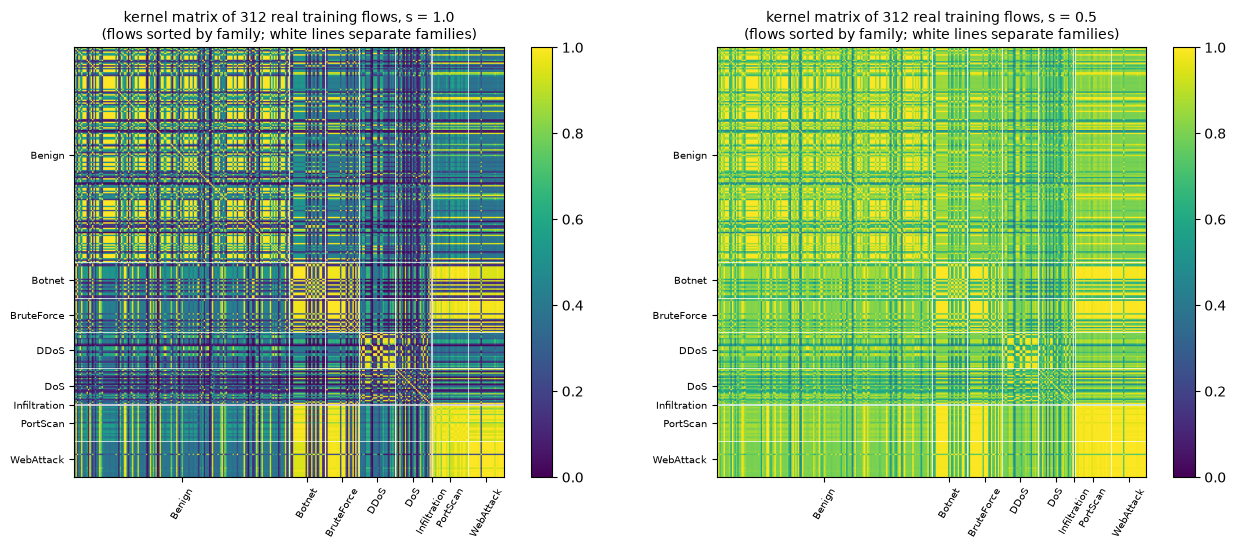

mean off-diagonal kernel value at s=1: 0.46


In [13]:
# Kernel matrices of real flows, ordered by family: what the SVM "sees". Left: paper-literal s=1. Right: s=0.5 (smoother).
sp = get_split("CIC-IDS2017 (balanced)", SEED)
order = np.argsort(sp["ftr"], kind="stable")[:: max(1, len(sp["ytr"]) // 300)]
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, s in zip(axes, (1.0, 0.5)):
    P = states_np(sp["Atr"][order], s); im = ax.imshow(gram(P, P), cmap="viridis", vmin=0, vmax=1)
    fam_o = sp["ftr"][order]; edges = [i for i in range(1, len(fam_o)) if fam_o[i] != fam_o[i - 1]]
    for e in edges: ax.axhline(e - .5, color="w", lw=.5); ax.axvline(e - .5, color="w", lw=.5)
    ax.set_title(f"kernel matrix of {len(order)} real training flows, s = {s}\n(flows sorted by family; white lines separate families)", fontsize=10)
    bounds = [0] + edges + [len(fam_o)]; mids = [(bounds[i] + bounds[i + 1]) / 2 - .5 for i in range(len(bounds) - 1)]; names_ = [fam_o[bounds[i]] for i in range(len(bounds) - 1)]
    ax.set_xticks(mids); ax.set_xticklabels(names_, rotation=60, fontsize=7); ax.set_yticks(mids); ax.set_yticklabels(names_, fontsize=7)
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()
print("mean off-diagonal kernel value at s=1:", round(float(np.mean(gram(states_np(sp['Atr'][order]), states_np(sp['Atr'][order]))[~np.eye(len(order), dtype=bool)])), 4))

## 6. Training: the quantum-kernel SVM and the three classical baselines

For every data set and seed:

* **QK-SVM (paper circuit, s = 1)**: kernel from the circuit exactly as in the paper; `C` in {0.1, 1, 10} by 3-fold stratified cross-validation on the training split; `SVC(kernel="precomputed")`.
* **QK-SVM (s tuned)**: the same, with the angle scale `s` chosen from `BANDWIDTHS` on a validation split of the training data only (`# CHOICE`, a standard step for quantum kernels; the paper does not tune it).
* **QK-SVM, 2 repetitions (extension, not in the paper)**: the entangled variant of Figure 3, also with `s` tuned.
* **Linear SVM**, **RBF-SVM**, **Random Forest (200 trees, balanced weights)**: on the **same 6 numbers** per flow, `C` from the same grid.
* For context, **Random Forest and RBF-SVM on all features** (the paper does not do this, but it shows what the 6-number compression costs).

Metrics as in the paper: train accuracy, test accuracy, F1, anomaly detection rate (= recall of the attack class); precision, weighted F1 and ROC-AUC are also stored. `t_fit` is training time (kernel construction + final fit + prediction), without the hyper-parameter search.

In [14]:
def metric_dict(y, p, score=None):
    return dict(prec=precision_score(y, p, zero_division=0), adr=recall_score(y, p), f1=f1_score(y, p, zero_division=0),
                f1w=f1_score(y, p, average="weighted", zero_division=0), acc=accuracy_score(y, p),
                auc=(roc_auc_score(y, score) if score is not None and len(np.unique(y)) > 1 else np.nan))

def pick_C(make, X, y, seed, precomputed=False):
    """3-fold stratified CV over C_GRID (paper, Section 5.5). Returns the C with the best mean accuracy (ties: smaller C)."""
    skf = StratifiedKFold(CV_FOLDS, shuffle=True, random_state=seed)
    best_C, best = None, -1
    for C in C_GRID:
        acc = []
        for a, b in skf.split(np.zeros(len(y)), y):
            m = make(C)
            if precomputed:
                m.fit(X[np.ix_(a, a)], y[a]); acc.append(accuracy_score(y[b], m.predict(X[np.ix_(b, a)])))
            else:
                m.fit(X[a], y[a]); acc.append(accuracy_score(y[b], m.predict(X[b])))
        if np.mean(acc) > best + 1e-12: best_C, best = C, float(np.mean(acc))
    return best_C

def run_qk(sp, reps, label, s_fixed=None):
    A_tr, A_te, ytr, yte, seed = sp["Atr"], sp["Ate"], sp["ytr"], sp["yte"], sp["seed"]
    t0 = time.perf_counter()
    if s_fixed is None:                                        # bandwidth on a validation split of the TRAINING data only
        itr, iva = train_test_split(np.arange(len(ytr)), test_size=VAL_FRAC, stratify=ytr, random_state=seed)
        val = {}
        for s in BANDWIDTHS:
            P = states_np(A_tr, s, reps); K = gram(P, P)
            m = SVC(kernel="precomputed", C=1.0).fit(K[np.ix_(itr, itr)], ytr[itr])
            val[s] = f1_score(ytr[iva], m.predict(K[np.ix_(iva, itr)]))
        s_best = max(val, key=val.get)
    else:
        s_best, val = s_fixed, {}
    P_tr = states_np(A_tr, s_best, reps); K_tr = gram(P_tr, P_tr)
    C = pick_C(lambda C: SVC(kernel="precomputed", C=C), K_tr, ytr, seed, precomputed=True)
    t_tune = time.perf_counter() - t0
    t1 = time.perf_counter()
    P_tr = states_np(A_tr, s_best, reps); K_tr = gram(P_tr, P_tr)
    m = SVC(kernel="precomputed", C=C).fit(K_tr, ytr)
    K_te = gram(states_np(A_te, s_best, reps), P_tr)
    p_te, sc_te, p_tr = m.predict(K_te), m.decision_function(K_te), m.predict(K_tr)
    t_fit = time.perf_counter() - t1
    row = dict(model=label, train_acc=accuracy_score(ytr, p_tr), t_fit=t_fit, t_tune=t_tune, s=s_best, C=C, **metric_dict(yte, p_te, sc_te))
    return row, p_te, sc_te, val

def run_sk(label, make, Xtr, ytr, Xte, yte, seed, tune=True):
    t0 = time.perf_counter()
    C = pick_C(make, Xtr, ytr, seed) if tune else None
    t_tune = time.perf_counter() - t0
    t1 = time.perf_counter()
    m = make(C) if tune else make(None)
    m.fit(Xtr, ytr); p_te, p_tr = m.predict(Xte), m.predict(Xtr)
    sc = m.predict_proba(Xte)[:, 1] if hasattr(m, "predict_proba") and not tune else m.decision_function(Xte)
    t_fit = time.perf_counter() - t1
    row = dict(model=label, train_acc=accuracy_score(ytr, p_tr), t_fit=t_fit, t_tune=t_tune, s=np.nan, C=C, **metric_dict(yte, p_te, sc))
    return row, p_te, sc

def run_all_models(sp, verbose=True):
    seed, rows, preds = sp["seed"], [], {}
    Atr, Ate, ytr, yte = sp["Atr"], sp["Ate"], sp["ytr"], sp["yte"]
    jobs = [("Linear SVM",   lambda: run_sk("Linear SVM", lambda C: LinearSVC(C=C, dual=False, max_iter=20000, random_state=seed), Atr, ytr, Ate, yte, seed)),
            ("RBF-SVM",      lambda: run_sk("RBF-SVM", lambda C: SVC(kernel="rbf", gamma="scale", C=C), Atr, ytr, Ate, yte, seed)),
            ("Random Forest", lambda: run_sk("Random Forest", lambda C: RandomForestClassifier(n_estimators=RF_TREES, class_weight="balanced", n_jobs=2, random_state=seed), Atr, ytr, Ate, yte, seed, tune=False)),
            ("QK-SVM (s=1, paper circuit)", lambda: run_qk(sp, 1, "QK-SVM (s=1, paper circuit)", s_fixed=1.0)[:3]),
            ("QK-SVM (s tuned)", lambda: run_qk(sp, 1, "QK-SVM (s tuned)")[:3])]
    if EXTENSION:
        jobs.append(("QK-SVM 2 reps (extension)", lambda: run_qk(sp, 2, "QK-SVM 2 reps (extension)")[:3]))
    Ftr, Fte = sp["prep"].full(sp["Xtr"]), np.clip(sp["prep"].full(sp["Xte"]), 0, 1)
    jobs += [("RF (all features)", lambda: run_sk("RF (all features)", lambda C: RandomForestClassifier(n_estimators=RF_TREES, class_weight="balanced", n_jobs=2, random_state=seed), Ftr, ytr, Fte, yte, seed, tune=False)),
             ("RBF-SVM (all features)", lambda: run_sk("RBF-SVM (all features)", lambda C: SVC(kernel="rbf", gamma="scale", C=C), Ftr, ytr, Fte, yte, seed))]
    for lab, job in jobs:
        t0 = time.perf_counter()
        out = job(); row = out[0]; row.update(dataset=sp["name"], seed=seed); rows.append(row); preds[lab] = (out[1], out[2])
        if verbose: print(f"    {lab:30s} test acc {row['acc']:.3f}  F1 {row['f1']:.3f}  ADR {row['adr']:.3f}  (C={row['C']}, s={row['s']})  [{time.perf_counter()-t0:.0f} s]", flush=True)
    return rows, preds

In [15]:
ROWS, PREDS = [], {}
t_all = time.perf_counter()
for name in CONFIGS:
    for seed in SEEDS:
        sp = get_split(name, seed)
        print(f"{name} | seed {seed} | train {len(sp['ytr'])} / test {len(sp['yte'])}", flush=True)
        rows, preds = run_all_models(sp)
        ROWS += rows; PREDS[(name, seed)] = preds
RES = pd.DataFrame(ROWS)
print(f"\nall experiments: {(time.perf_counter()-t_all)/60:.1f} min")

def summary(res, cols=("train_acc", "acc", "f1", "adr", "prec", "auc", "t_fit")):
    g = res.groupby(["dataset", "model"], sort=False)
    mean, std = g[list(cols)].mean(), g[list(cols)].std(ddof=0)
    out = mean.copy()
    for c in cols:
        out[c] = [f"{m:.3f} +/- {s:.3f}" if c != "t_fit" else f"{m:.1f} s" for m, s in zip(mean[c], std[c])]
    return out
SUM = summary(RES)
for name in CONFIGS:
    _y = get_split(name, SEED)["yte"]
    print("\n" + name + f"   (majority-class accuracy of a classifier that always answers the larger class: {max(_y.mean(), 1 - _y.mean()):.3f})"); print(SUM.loc[name].rename(columns={"acc": "test_acc", "adr": "anomaly_detection_rate"}).to_string())

CIC-IDS2017 (balanced) | seed 42 | train 5600 / test 2400


    Linear SVM                     test acc 0.785  F1 0.808  ADR 0.903  (C=10, s=nan)  [0 s]

    RBF-SVM                        test acc 0.880  F1 0.886  ADR 0.927  (C=10, s=nan)  [15 s]


    Random Forest                  test acc 0.975  F1 0.975  ADR 0.978  (C=None, s=nan)  [3 s]


    QK-SVM (s=1, paper circuit)    test acc 0.874  F1 0.881  ADR 0.927  (C=10, s=1.0)  [9 s]


...

    QK-SVM (s tuned)               test acc 0.791  F1 0.757  ADR 0.651  (C=10, s=2.0)  [18 s]


    QK-SVM 2 reps (extension)      test acc 0.786  F1 0.753  ADR 0.654  (C=10, s=2.0)  [22 s]


    RF (all features)              test acc 0.856  F1 0.849  ADR 0.809  (C=None, s=nan)  [3 s]


    RBF-SVM (all features)         test acc 0.811  F1 0.782  ADR 0.677  (C=10, s=nan)  [27 s]



all experiments: 15.8 min

CIC-IDS2017 (balanced)   (majority-class accuracy of a classifier that always answers the larger class: 0.500)
                                   train_acc         test_acc               f1 anomaly_detection_rate             prec              auc  t_fit
model                                                                                                                                         
Linear SVM                   0.774 +/- 0.009  0.772 +/- 0.011  0.792 +/- 0.013        0.867 +/- 0.028  0.729 +/- 0.003  0.828 +/- 0.005  0.0 s
RBF-SVM                      0.885 +/- 0.005  0.879 +/- 0.002  0.884 +/- 0.002        0.922 +/- 0.003  0.848 +/- 0.001  0.951 +/- 0.002  4.5 s
Random Forest                1.000 +/- 0.000  0.971 +/- 0.004  0.971 +/- 0.004        0.978 +/- 0.004  0.964 +/- 0.006  0.995 +/- 0.001  2.8 s
QK-SVM (s=1, paper circuit)  0.879 +/- 0.003  0.871 +/- 0.003  0.877 +/- 0.003        0.918 +/- 0.007  0.839 +/- 0.000  0.942 +/- 0.001  2.7 s
QK-

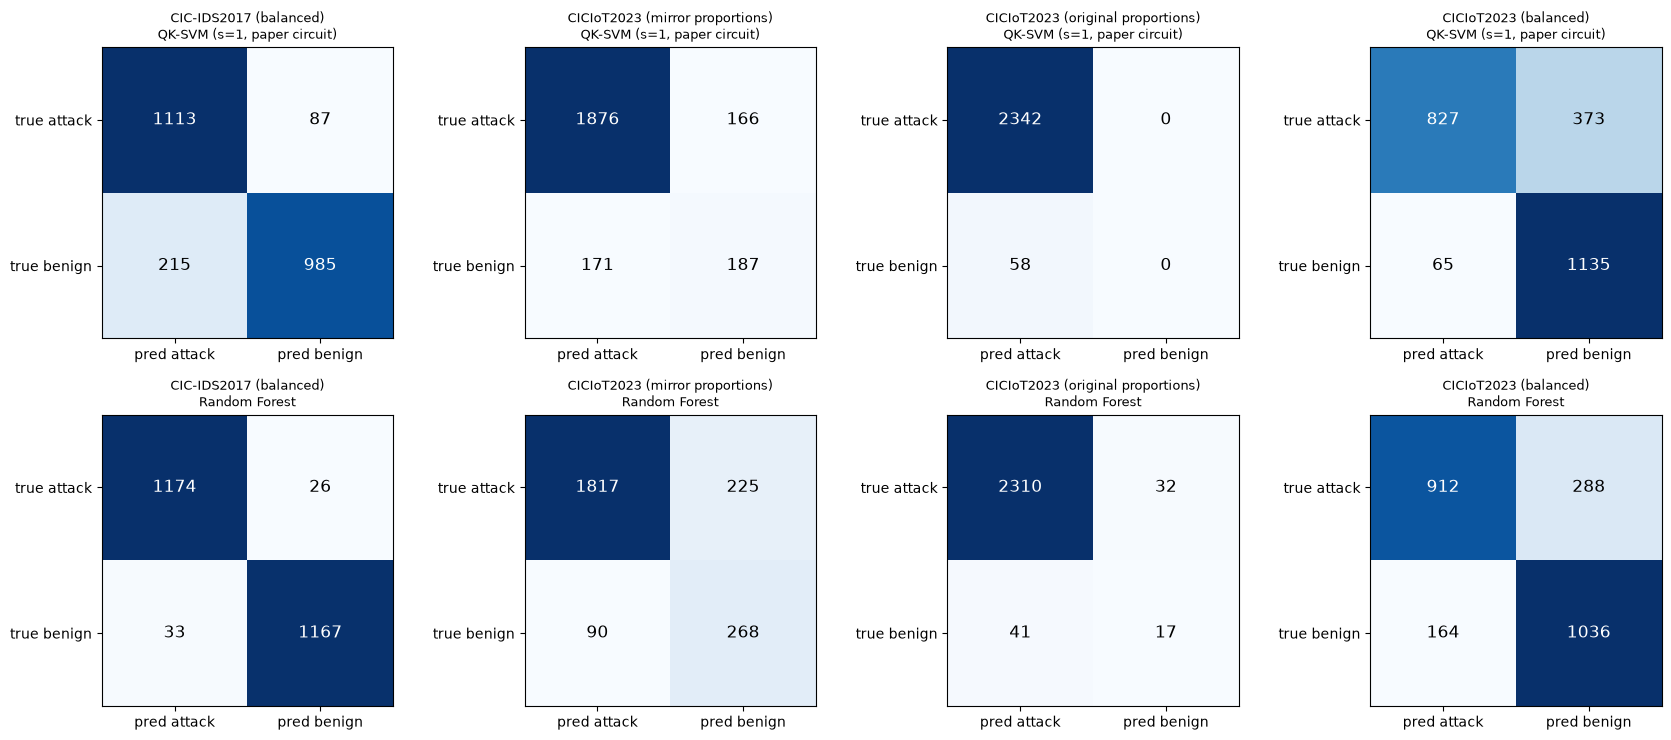

share of test flows classified correctly, per family (for 'Benign' this is the specificity):
model                                                QK-SVM (s tuned)  QK-SVM (s=1, paper circuit)  RBF-SVM  Random Forest
dataset                           family       n                                                                          
CIC-IDS2017 (balanced)            Benign       1200             0.882                        0.821    0.834          0.972
                                  Botnet       198              0.783                        0.778    0.773          0.990
                                  BruteForce   198              1.000                        1.000    1.000          1.000
                                  DDoS         198              0.949                        0.995    0.995          0.985
                                  DoS          199              0.824                        0.879    0.889          0.960
                                  Infiltration

In [16]:
# Confusion matrices (attack = positive class), seed SEED, QK-SVM (paper circuit) and Random Forest
fig, axes = plt.subplots(2, len(CONFIGS), figsize=(4.3 * len(CONFIGS), 7.5))
for j, name in enumerate(CONFIGS):
    sp = get_split(name, SEED)
    for i, mdl in enumerate(("QK-SVM (s=1, paper circuit)", "Random Forest")):
        cm = confusion_matrix(sp["yte"], PREDS[(name, SEED)][mdl][0], labels=[1, 0])
        ax = axes[i, j]; ax.imshow(cm, cmap="Blues")
        for (a, b), v in np.ndenumerate(cm): ax.text(b, a, f"{v}", ha="center", va="center", color="white" if v > cm.max() / 2 else "black", fontsize=12)
        ax.set_xticks([0, 1]); ax.set_xticklabels(["pred attack", "pred benign"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["true attack", "true benign"])
        ax.set_title(f"{name}\n{mdl}", fontsize=9)
plt.tight_layout(); plt.show()

# detection rate per attack family (seed SEED): which attacks does the 6-qubit kernel miss?
fam_rows = []
for name in CONFIGS:
    sp = get_split(name, SEED)
    for mdl in ("QK-SVM (s=1, paper circuit)", "QK-SVM (s tuned)", "RBF-SVM", "Random Forest"):
        p = PREDS[(name, SEED)][mdl][0]
        for f in sorted(set(sp["fte"])):
            m = sp["fte"] == f
            fam_rows.append(dict(dataset=name, model=mdl, family=f, n=int(m.sum()), recall=float((p[m] == (0 if f == "Benign" else 1)).mean())))
FAM = pd.DataFrame(fam_rows)
print("share of test flows classified correctly, per family (for 'Benign' this is the specificity):")
print(FAM.pivot_table(index=["dataset", "family", "n"], columns="model", values="recall").round(3).to_string())

## 7. Re-drawing the paper's Figures 6 and 7 and Table 6

The paper's Figures 6 and 7 compare the four models on accuracy, F1 and anomaly detection rate. Left of each pair: the paper's numbers (Tables 4 and 5). Right: this notebook's numbers (mean over seeds; bars show the standard deviation when there are several seeds).

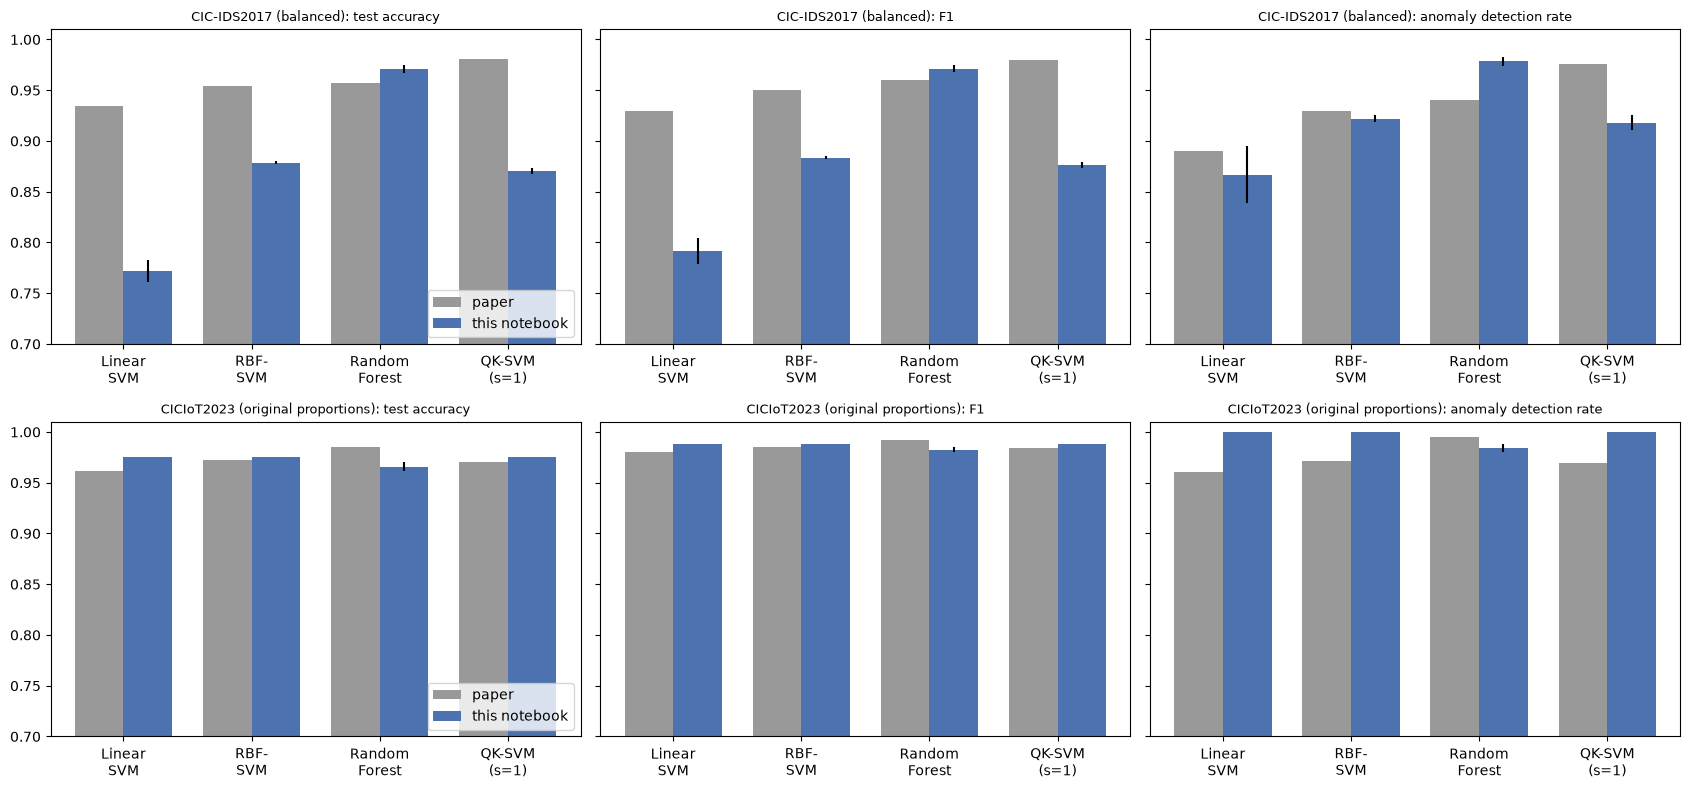

Table 6 analogue (training time; different machine, different sample size, NumPy kernel):
               paper training time (s)  this notebook, CIC-IDS2017 balanced (s)  this notebook, CICIoT2023 mirror proportions (s)  this notebook, CICIoT2023 original proportions (s)  this notebook, CICIoT2023 balanced (s)
Linear SVM                      289.46                                     0.01                                              0.01                                                0.02                                    0.02
RBF-SVM                          64.91                                     4.49                                              3.40                                                0.63                                    6.78
Random Forest                    84.49                                     2.76                                              3.68                                                2.07                                    3.40
QK-SVM                

In [17]:
PAPER = {   # Tables 4 and 5 of the paper: model -> (train acc, test acc, F1, anomaly detection rate)
    "CIC-IDS2017": {"Linear SVM": (0.962, 0.934, 0.93, 0.89), "RBF-SVM": (0.981, 0.954, 0.95, 0.93), "Random Forest": (0.988, 0.957, 0.96, 0.94), "QK-SVM": (0.994, 0.981, 0.98, 0.976)},
    "CICIoT2023":  {"Linear SVM": (0.955, 0.962, 0.980, 0.961), "RBF-SVM": (0.968, 0.972, 0.985, 0.971), "Random Forest": (1.000, 0.985, 0.992, 0.995), "QK-SVM": (0.968, 0.970, 0.984, 0.969)},
}
PAPER_T6 = {"Linear SVM": 289.4622, "RBF-SVM": 64.9128, "Random Forest": 84.4928, "QK-SVM": 929.6840}      # Table 6, training time in seconds
MODELS4 = ["Linear SVM", "RBF-SVM", "Random Forest", "QK-SVM (s=1, paper circuit)"]
mean_by = RES.groupby(["dataset", "model"]).mean(numeric_only=True); std_by = RES.groupby(["dataset", "model"]).std(ddof=0, numeric_only=True).fillna(0)
mets = [("acc", "test accuracy", 1), ("f1", "F1", 2), ("adr", "anomaly detection rate", 3)]
fig, axes = plt.subplots(2, 3, figsize=(17, 8), sharey=True)
for r, (name, pk) in enumerate((("CIC-IDS2017 (balanced)", "CIC-IDS2017"), ("CICIoT2023 (original proportions)", "CICIoT2023"))):
    for c, (key, ttl, col) in enumerate(mets):
        ax = axes[r, c]; w = 0.38; xs = np.arange(4)
        ax.bar(xs - w / 2, [PAPER[pk][m if m != MODELS4[3] else "QK-SVM"][col] for m in MODELS4], w, label="paper", color="#999999")
        ax.bar(xs + w / 2, [mean_by.loc[(name, m), key] for m in MODELS4], w, yerr=[std_by.loc[(name, m), key] for m in MODELS4], label="this notebook", color="#4c72b0")
        ax.set_xticks(xs); ax.set_xticklabels(["Linear\nSVM", "RBF-\nSVM", "Random\nForest", "QK-SVM\n(s=1)"]); ax.set_ylim(0.7, 1.01); ax.set_title(f"{name}: {ttl}", fontsize=9)
        if c == 0: ax.legend(loc="lower right")
plt.tight_layout(); plt.show()
t6 = pd.DataFrame({"paper training time (s)": PAPER_T6,
                   **{f"this notebook, {n.split(' (')[0]} {n.split('(')[1][:-1]} (s)": {k: mean_by.loc[(n, v), "t_fit"] for k, v in zip(PAPER_T6, MODELS4)} for n in CONFIGS}})
print("Table 6 analogue (training time; different machine, different sample size, NumPy kernel):"); print(t6.round(2).to_string())
n_pairs = int(np.ceil(len(get_split("CIC-IDS2017 (balanced)", SEED)["ytr"]) ** 2))
print(f"\nFor reference: the Qiskit FidelityStatevectorKernel needs ~{T_FSK_PAIR*1e6:.0f} microseconds per pair here, i.e. about {T_FSK_PAIR*n_pairs/60:.1f} min for the {n_pairs:,}-entry training Gram matrix of this run (the NumPy path takes seconds).")

## 8. NISQ noise study with an IBM fake backend

The paper claims "noise-aware simulation analysis to assess robustness under realistic quantum hardware conditions" (contribution 5) but reports no noise numbers. This section runs the compute-uncompute circuit of Figure 2 for every pair of a small set of real flows under four conditions and trains the SVM on the resulting kernel:

| Condition | What it is |
|---|---|
| exact | the statevector kernel used everywhere above |
| shots only | noiseless Aer simulation with `SHOTS` shots per pair (sampling noise of the estimate `P(000000)`) |
| device noise, circuit as written | `FakeSherbrooke` (127-qubit IBM Eagle device, `qiskit_ibm_runtime.fake_provider`) gate/readout noise model with `AerSimulator.from_backend`; transpiled with `optimization_level=0` onto a 6-qubit path of the coupling map, so the `CZ` gates are really executed (as `ECR` gates plus routing) |
| device noise, optimised circuit | the same device, `optimization_level=3`: the transpiler discovers that the two `CZ` chains cancel (Section 5) and removes them, leaving only single-qubit gates |

Only a small number of flows is used, because every pair is a separate noisy circuit (one `AerSimulator` run per pair). Test accuracy on `N_NOISE_TEST` flows has a resolution of a few percentage points, so compare the **kernel error** (mean absolute difference to the exact kernel) rather than small accuracy changes. Non-positive-semidefinite noisy kernels are repaired by clipping negative eigenvalues (as `QSVC(enforce_psd=True)` does).

device: fake_sherbrooke | qubits: 127 | 6-qubit path used as initial layout: [0, 1, 2, 3, 4, 5]


shots only                     depth  13 | two-qubit gates 10 | gates {'ry': 12, 'cz': 10}
device, circuit as written     depth 143 | two-qubit gates 10 | gates {'rz': 190, 'sx': 86, 'ecr': 10, 'x': 10}
device, optimised circuit      depth   7 | two-qubit gates  0 | gates {'rz': 24, 'sx': 12}

Figure 4: the compute-uncompute circuit as executed on the fake device when written literally (optimization_level=0):


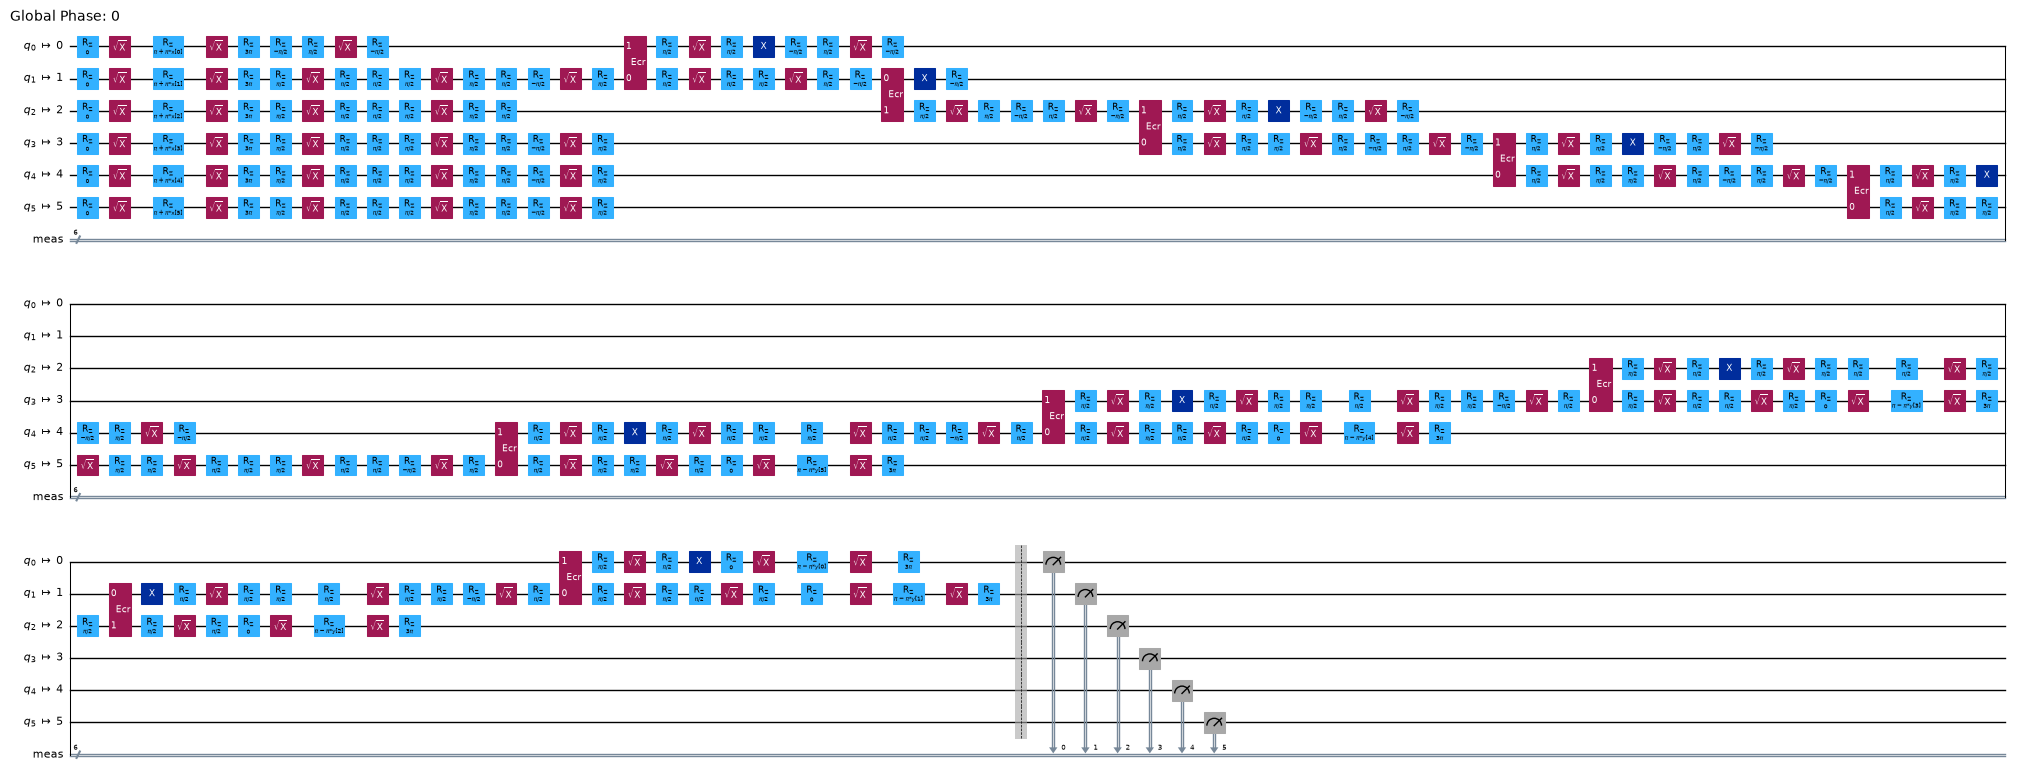

In [18]:
from qiskit_ibm_runtime.fake_provider import FakeSherbrooke
backend = FakeSherbrooke()
sim_dev = AerSimulator.from_backend(backend, seed_simulator=SEED)

def find_path(cmap, n):
    """First simple path with n qubits in the (undirected) coupling map, found by depth-first search from qubit 0 upwards."""
    adj = {}
    for a, b in cmap.get_edges(): adj.setdefault(a, set()).add(b); adj.setdefault(b, set()).add(a)
    def dfs(path):
        if len(path) == n: return path
        for nb in sorted(adj[path[-1]]):
            if nb not in path:
                r = dfs(path + [nb])
                if r: return r
        return None
    for s0 in sorted(adj):
        r = dfs([s0])
        if r: return r
PATH = find_path(backend.coupling_map, N_QUBITS)
print("device:", backend.name, "| qubits:", backend.num_qubits, "| 6-qubit path used as initial layout:", PATH)

TC = {"shots only": transpile(KC1, AerSimulator(), optimization_level=0, seed_transpiler=SEED),
      "device, circuit as written": transpile(KC1, backend, optimization_level=0, initial_layout=PATH, seed_transpiler=SEED),
      "device, optimised circuit": transpile(KC1, backend, optimization_level=3, initial_layout=PATH, seed_transpiler=SEED)}
for k, t in TC.items():
    ops = {g: c for g, c in t.count_ops().items() if g not in ("measure", "barrier")}
    print(f"{k:30s} depth {t.depth():3d} | two-qubit gates {sum(c for g, c in ops.items() if g in ('ecr','cz','cx')):2d} | gates {ops}")
print("\nFigure 4: the compute-uncompute circuit as executed on the fake device when written literally (optimization_level=0):")
display(TC["device, circuit as written"].draw("mpl", fold=60, scale=0.5, idle_wires=False))

shots only                     done in    20 s (2775 circuits)


device, circuit as written     done in   302 s (2775 circuits)


device, optimised circuit      done in   187 s (2775 circuits)



kernel study on 50 training and 30 test flows of CIC-IDS2017 (s = 1, SHOTS = 1024); RBF-SVM on the same flows: test acc 0.667
                            mean_abs_kernel_error  mean_abs_error_test_rows  mean_offdiag_kernel  test_acc      f1   seconds
condition                                                                                                                   
exact                                      0.0000                    0.0000               0.5280    0.6667  0.6667    0.0000
shots only                                 0.0090                    0.0093               0.5275    0.6333  0.6452   20.2275
device, circuit as written                 0.1216                    0.1011               0.4092    0.6333  0.6207  301.6662
device, optimised circuit                  0.0738                    0.0613               0.4561    0.6333  0.6207  186.6697


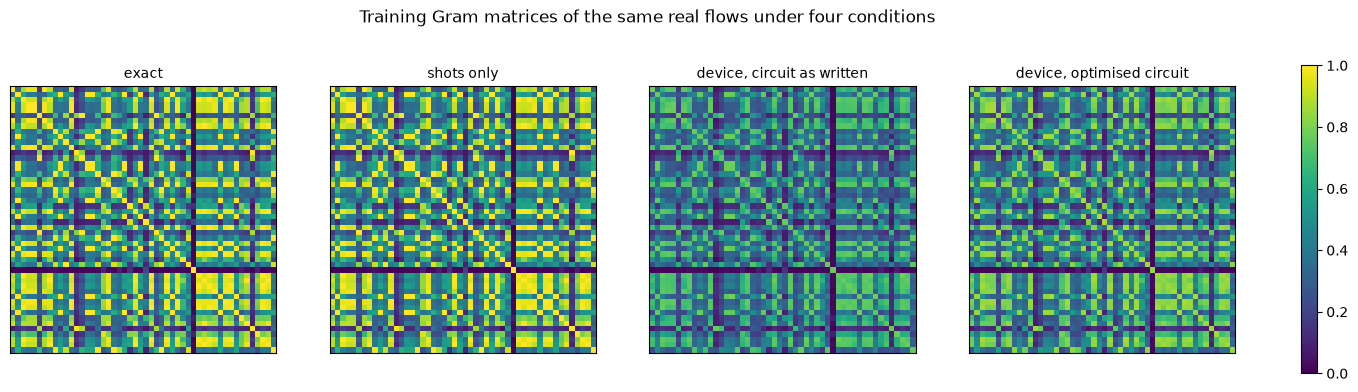

In [19]:
def run_gram(tc, sim, XA_, XB_, scale, shots, seed):
    """Estimate K(a, b) = P(000000) for every pair with the transpiled compute-uncompute circuit. Returns the (len(A), len(B)) matrix."""
    params = KC_X + KC_Y
    jobs = [tc.assign_parameters(dict(zip(params, np.concatenate([scale * a, scale * b])))) for a in XA_ for b in XB_]
    out = []
    for k in range(0, len(jobs), 150):
        res = sim.run(jobs[k:k + 150], shots=shots, seed_simulator=seed + k).result()
        out += [res.get_counts(i).get("0" * N_QUBITS, 0) / shots for i in range(len(jobs[k:k + 150]))]
    return np.array(out).reshape(len(XA_), len(XB_))

def sym_gram(tc, sim, X_, scale, shots, seed):
    """Symmetric training Gram matrix: upper triangle simulated once, diagonal = 1 for the exact kernel, simulated for the noisy ones."""
    n = len(X_); K = np.zeros((n, n))
    for i in range(n):
        K[i, i:] = run_gram(tc, sim, X_[i:i + 1], X_[i:], scale, shots, seed + 1000 * i)[0]
        K[i:, i] = K[i, i:]
    return K

def make_psd(K):
    w, V = np.linalg.eigh((K + K.T) / 2); return (V * np.clip(w, 0, None)) @ V.T

sp = get_split("CIC-IDS2017 (balanced)", SEED)
rn = np.random.default_rng(SEED)
def strat_pick(y, n, rg):
    a = rg.choice(np.flatnonzero(y == 1), n // 2, replace=False); b = rg.choice(np.flatnonzero(y == 0), n - n // 2, replace=False)
    return np.sort(np.concatenate([a, b]))
itr_n, ite_n = strat_pick(sp["ytr"], N_NOISE_TRAIN, rn), strat_pick(sp["yte"], N_NOISE_TEST, rn)
Xn_tr, yn_tr, Xn_te, yn_te = sp["Atr"][itr_n], sp["ytr"][itr_n], sp["Ate"][ite_n], sp["yte"][ite_n]
S = 1.0     # the paper-literal circuit
P_tr, P_te = states_np(Xn_tr, S), states_np(Xn_te, S)
K_exact_tr, K_exact_te = gram(P_tr, P_tr), gram(P_te, P_tr)

NOISE = {"exact": (K_exact_tr, K_exact_te, 0.0)}
t0 = time.perf_counter()
for cond, sim in (("shots only", AerSimulator(seed_simulator=SEED)), ("device, circuit as written", sim_dev), ("device, optimised circuit", sim_dev)):
    t1 = time.perf_counter()
    Ktr = sym_gram(TC[cond], sim, Xn_tr, S, SHOTS, SEED)
    Kte = run_gram(TC[cond], sim, Xn_te, Xn_tr, S, SHOTS, SEED + 7)
    NOISE[cond] = (Ktr, Kte, time.perf_counter() - t1)
    print(f"{cond:30s} done in {time.perf_counter()-t1:5.0f} s ({Ktr.shape[0]*(Ktr.shape[0]+1)//2 + Kte.size} circuits)", flush=True)

rows = []
for cond, (Ktr, Kte, tt) in NOISE.items():
    Kp = make_psd(Ktr) if cond != "exact" else Ktr
    m = SVC(kernel="precomputed", C=1.0).fit(Kp, yn_tr); p = m.predict(Kte)
    rows.append(dict(condition=cond, mean_abs_kernel_error=float(np.abs(Ktr - K_exact_tr).mean()), mean_abs_error_test_rows=float(np.abs(Kte - K_exact_te).mean()),
                     mean_offdiag_kernel=float(Ktr[~np.eye(len(Ktr), dtype=bool)].mean()), test_acc=accuracy_score(yn_te, p), f1=f1_score(yn_te, p), seconds=tt))
NOISE_DF = pd.DataFrame(rows).set_index("condition")
rbf = SVC(kernel="rbf", gamma="scale", C=1.0).fit(Xn_tr, yn_tr)
print(f"\nkernel study on {len(yn_tr)} training and {len(yn_te)} test flows of CIC-IDS2017 (s = 1, SHOTS = {SHOTS}); RBF-SVM on the same flows: test acc {accuracy_score(yn_te, rbf.predict(Xn_te)):.3f}")
print(NOISE_DF.round(4).to_string())

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, (cond, (Ktr, _, _)) in zip(axes, NOISE.items()):
    im = ax.imshow(Ktr, vmin=0, vmax=1, cmap="viridis"); ax.set_title(cond, fontsize=10); ax.set_xticks([]); ax.set_yticks([])
plt.colorbar(im, ax=axes, fraction=0.02); plt.suptitle("Training Gram matrices of the same real flows under four conditions", y=1.02); plt.show()

**Reading the noise study.** Sampling noise alone gives an absolute error of roughly `1/sqrt(SHOTS)` in every kernel entry (first noisy row of the table). Device noise adds a systematic bias on top: readout and gate errors push probability away from the all-zero outcome, so the kernel values are pulled down (compare `mean_offdiag_kernel` with the exact row). The circuit as written is much deeper than the optimised one because it contains the `CZ` chains that mathematically cancel (Figure 4: `ECR` gates plus single-qubit gates; the table above the figure gives depth and gate counts). With the optimised circuit the transpiler removes the entangling gates entirely and the noise reduces to single-qubit and readout errors, with a visibly smaller kernel error. The paper's claim that the circuit is "NISQ-compatible" is therefore true mostly because the circuit is trivial: it is a product circuit once the cancellation is exploited, and it needs no quantum hardware at all.

*Real hardware.* The paper reports **no** hardware runs ("experimental verification on a quantum processor is not claimed"), so there is nothing to compare. The cell below runs a handful of kernel entries on an IBM device **only** if you set `IBM_TOKEN`; it is skipped otherwise.

In [20]:
if IBM_TOKEN:
    from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2
    service = QiskitRuntimeService(channel="ibm_quantum_platform", token=IBM_TOKEN)
    hw = service.least_busy(operational=True, simulator=False, min_num_qubits=N_QUBITS)
    tc_hw = transpile(KC1, hw, optimization_level=0, seed_transpiler=SEED)
    pairs_hw = [(Xn_te[i], Xn_tr[i]) for i in range(10)]
    pubs = [(tc_hw, [np.concatenate([a, b])]) for a, b in pairs_hw]
    # parameter order of tc_hw follows KC_X + KC_Y only after assign_parameters; bind explicitly to be safe
    pubs = [(tc_hw.assign_parameters(dict(zip(KC_X + KC_Y, np.concatenate([a, b])))),) for a, b in pairs_hw]
    job = SamplerV2(mode=hw).run(pubs, shots=SHOTS)
    p_hw = [r.data.meas.get_counts().get("0" * N_QUBITS, 0) / SHOTS for r in job.result()]
    p_ex = [gram(states_np(a[None]), states_np(b[None]))[0, 0] for a, b in pairs_hw]
    print(hw.name, "hardware:", np.round(p_hw, 3)); print("exact   :", np.round(p_ex, 3))
else:
    print("IBM_TOKEN is empty: the real-hardware cell is skipped. The paper reports no hardware results, so the hardware claim is 'cannot be checked'.")

IBM_TOKEN is empty: the real-hardware cell is skipped. The paper reports no hardware results, so the hardware claim is 'cannot be checked'.


## 9. Sensitivity check: does the scaling order in the paper matter?

Algorithm 1 scales every feature to [0, 1] with min-max *before* the PCA. Flow features such as `Flow Bytes/s` have enormous outliers, and min-max scaling squeezes the bulk of the flows into a tiny range, so the PCA is dominated by a few outlier-driven directions. The notebook's reference conventions use `StandardScaler` before the PCA instead. The check below repeats the main comparison with `StandardScaler` (first seed, same samples and splits) to see how much of the picture depends on this unspecified detail.

In [21]:
def split_with_mode(sp, mode):
    prep = Prep(mode=mode, seed=sp["seed"]).fit(sp["Xtr"])
    Ptr, Atr = prep.stages(sp["Xtr"]); Pte, Ate = prep.stages(sp["Xte"])
    return {**sp, "prep": prep, "Ptr": Ptr, "Atr": Atr, "Pte": Pte, "Ate": Ate}

SENS = []
for name in ("CIC-IDS2017 (balanced)", "CICIoT2023 (mirror proportions)"):
    sp = get_split(name, SEED); sps = split_with_mode(sp, "standard")
    seed = SEED
    for lab, job in (("QK-SVM (s=1)", lambda: run_qk(sps, 1, "q", s_fixed=1.0)[0]),
                     ("QK-SVM (s tuned)", lambda: run_qk(sps, 1, "q")[0]),
                     ("RBF-SVM", lambda: run_sk("r", lambda C: SVC(kernel="rbf", gamma="scale", C=C), sps["Atr"], sps["ytr"], sps["Ate"], sps["yte"], seed)[0]),
                     ("Random Forest", lambda: run_sk("f", lambda C: RandomForestClassifier(n_estimators=RF_TREES, class_weight="balanced", n_jobs=2, random_state=seed), sps["Atr"], sps["ytr"], sps["Ate"], sps["yte"], seed, tune=False)[0])):
        r = job(); SENS.append(dict(dataset=name, model=lab, variance_kept=sps["prep"].explained, test_acc=r["acc"], f1=r["f1"], adr=r["adr"], s=r["s"]))
    base = RES[(RES.dataset == name) & (RES.seed == SEED)].set_index("model")
    for lab, key in (("QK-SVM (s=1)", "QK-SVM (s=1, paper circuit)"), ("QK-SVM (s tuned)", "QK-SVM (s tuned)"), ("RBF-SVM", "RBF-SVM"), ("Random Forest", "Random Forest")):
        SENS.append(dict(dataset=name, model=lab + "  [paper: min-max -> PCA]", variance_kept=get_split(name, SEED)["prep"].explained, test_acc=base.loc[key, "acc"], f1=base.loc[key, "f1"], adr=base.loc[key, "adr"], s=base.loc[key, "s"]))
SENS = pd.DataFrame(SENS).sort_values(["dataset", "model"])
print("StandardScaler -> PCA(6)   versus   the paper's MinMax -> PCA(6):"); print(SENS.round(3).to_string(index=False))

StandardScaler -> PCA(6)   versus   the paper's MinMax -> PCA(6):
                        dataset                                     model  variance_kept  test_acc    f1   adr   s
         CIC-IDS2017 (balanced)                          QK-SVM (s tuned)          0.608     0.845 0.853 0.900 2.0
         CIC-IDS2017 (balanced) QK-SVM (s tuned)  [paper: min-max -> PCA]          0.824     0.899 0.900 0.916 2.0
         CIC-IDS2017 (balanced)                              QK-SVM (s=1)          0.608     0.809 0.798 0.753 1.0
         CIC-IDS2017 (balanced)     QK-SVM (s=1)  [paper: min-max -> PCA]          0.824     0.874 0.881 0.928 1.0
         CIC-IDS2017 (balanced)                                   RBF-SVM          0.608     0.821 0.820 0.812 NaN
         CIC-IDS2017 (balanced)          RBF-SVM  [paper: min-max -> PCA]          0.824     0.880 0.886 0.927 NaN
         CIC-IDS2017 (balanced)                             Random Forest          0.608     0.973 0.973 0.968 NaN
         CIC-I

## 10. Side-by-side comparison with the paper

Rule: a paper value is "reproduced" when this notebook's mean is within 0.02 of it (accuracy points or F1 / rate), "exceeded" or "not reached" otherwise with the gap, and "cannot be checked" when the notebook cannot test it. The comparison uses the paper-literal circuit (`s = 1`); the tuned variant is listed separately for context. Our CICIoT2023 comparison uses the **original-proportion** sample (97.6 % attack): this is a conjecture about the paper's data (its F1 is higher than its accuracy and its anomaly detection rate is close to its accuracy, which happens when the attack class dominates the test set), and the majority-class accuracy of that sample is printed in Section 6. The mirror-proportion and balanced variants are listed as context.

In [22]:
def verdict(paper, mine, tol=0.02):
    if mine is None or (isinstance(mine, float) and np.isnan(mine)): return "cannot be checked"
    gap = float(mine) - float(paper)
    return "reproduced" if abs(gap) <= tol else (f"exceeded (gap {gap:+.3f})" if gap > 0 else f"not reached (gap {gap:+.3f})")
CLAIMS = []
def add(claim, paper, mine, tol=0.02, v=None):
    CLAIMS.append(dict(claim=claim, paper=paper, notebook=((int(mine) if float(mine).is_integer() and abs(mine) >= 2 else round(float(mine), 3)) if isinstance(mine, (int, float, np.floating)) and not pd.isna(mine) else mine),
                       verdict=v if v is not None else verdict(paper, mine, tol)))

LAB = {0: "train accuracy", 1: "test accuracy", 2: "F1", 3: "anomaly detection rate"}; KEY = {0: "train_acc", 1: "acc", 2: "f1", 3: "adr"}
RUNS = {"CIC-IDS2017": "CIC-IDS2017 (balanced)", "CICIoT2023": "CICIoT2023 (original proportions)"}
for pk, name in RUNS.items():
    for pm, nm in zip(("Linear SVM", "RBF-SVM", "Random Forest", "QK-SVM"), MODELS4):
        for i in range(4):
            add(f"{pk} Table {4 if pk=='CIC-IDS2017' else 5}: {pm} {LAB[i]}", PAPER[pk][pm][i], mean_by.loc[(name, nm), KEY[i]])
    for i in (1, 2, 3):
        add(f"{pk}: QK-SVM with tuned s, {LAB[i]} (context)", PAPER[pk]["QK-SVM"][i], mean_by.loc[(name, "QK-SVM (s tuned)"), KEY[i]])

for nm_ in ("CICIoT2023 (mirror proportions)", "CICIoT2023 (balanced)"):
    for i in (1, 2):
        add(f"CICIoT2023, {nm_.split('(')[1][:-1]} sample: QK-SVM {LAB[i]} (context)", PAPER["CICIoT2023"]["QK-SVM"][i], mean_by.loc[(nm_, "QK-SVM (s=1, paper circuit)"), KEY[i]])
_yo = get_split("CICIoT2023 (original proportions)", SEED)["yte"]
add("CICIoT2023: QK-SVM test accuracy exceeds the majority-class baseline of the sample", f"0.970 vs {max(_yo.mean(), 1-_yo.mean()):.3f} (original proportions)", mean_by.loc[("CICIoT2023 (original proportions)", "QK-SVM (s=1, paper circuit)"), "acc"], v="no (the accuracy equals or is below that of always answering attack)" if mean_by.loc[("CICIoT2023 (original proportions)", "QK-SVM (s=1, paper circuit)"), "acc"] <= max(_yo.mean(), 1-_yo.mean()) + 1e-9 else "yes")
g = lambda name, mdl, k="acc": mean_by.loc[(name, mdl), k]
c, io = RUNS["CIC-IDS2017"], RUNS["CICIoT2023"]
Q = "QK-SVM (s=1, paper circuit)"
add("CIC-IDS2017: QK-SVM has the highest test accuracy of the 4 models", "yes", "yes" if g(c, Q) >= max(g(c, m) for m in MODELS4[:3]) else "no", v="reproduced" if g(c, Q) >= max(g(c, m) for m in MODELS4[:3]) else f"not reached (QK {g(c,Q):.3f} vs best classical {max(g(c,m) for m in MODELS4[:3]):.3f})")
add("CIC-IDS2017: QK-SVM beats Random Forest (test accuracy)", "yes (+0.024)", f"{g(c,Q)-g(c,'Random Forest'):+.3f}", v="reproduced" if g(c, Q) > g(c, "Random Forest") + 0.01 else "not reached")
add("CIC-IDS2017: QK-SVM beats RBF-SVM (test accuracy)", "yes (+0.027)", f"{g(c,Q)-g(c,'RBF-SVM'):+.3f}", v="reproduced" if g(c, Q) > g(c, "RBF-SVM") + 0.01 else "not reached")
add("CICIoT2023: Random Forest >= QK-SVM (test accuracy)", "yes (+0.015)", f"{g(io,'Random Forest')-g(io,Q):+.3f}", v="reproduced" if g(io, "Random Forest") >= g(io, Q) else "not reached")
add("CICIoT2023: QK-SVM within 2 points of Random Forest", "yes", f"{abs(g(io,'Random Forest')-g(io,Q)):.3f}", v="reproduced" if abs(g(io, "Random Forest") - g(io, Q)) <= 0.02 else "not reached")
for pk, name in RUNS.items():
    add(f"{pk}: 6 PCA components keep >= 95 % of the variance", 0.95, get_split(name, SEED)["prep"].explained, v=("reproduced" if get_split(name, SEED)["prep"].explained >= 0.95 else f"not reached ({get_split(name, SEED)['prep'].explained:.3f})"))
add("CIC-IDS2017: train-test accuracy gap of QK-SVM (small)", 0.013, mean_by.loc[(c, Q), "train_acc"] - mean_by.loc[(c, Q), "acc"], 0.02)
add("Table 7: F1 of QK-SVM on CIC-IDS2017 = 98.1 %", 0.981, g(c, Q, "f1")); add("Table 7: F1 of QK-SVM on CICIoT2023 = 98.1 %", 0.981, g(io, Q, "f1"))
tt = {m: mean_by.loc[(c, m), "t_fit"] for m in MODELS4}
add("Table 6: QK-SVM is the most expensive to train (here: NumPy kernel)", "yes (929.7 s vs 65-289 s)", f"{tt[Q]:.1f} s vs {min(tt[m] for m in MODELS4[:3]):.1f}-{max(tt[m] for m in MODELS4[:3]):.1f} s",
    v="reproduced" if tt[Q] > max(tt[m] for m in MODELS4[:3]) else "not reached (the NumPy kernel is cheap; the Qiskit class would need " + f"~{T_FSK_PAIR*len(get_split(c, SEED)['ytr'])**2/60:.0f} min)")
add("Table 6: absolute training times (s)", "289 / 65 / 84 / 930", "hardware- and size-dependent", v="cannot be checked")
add("Section 4.2.2: the CZ entanglement layer captures feature correlations in the kernel", "yes", "kernel = product of cosines (Section 5); max |diff| < 1e-12", v="not supported (the CZ chain cancels in the kernel)")
add("Contribution 5: robustness under realistic NISQ noise", "no numbers given", f"kernel error: shots {NOISE_DF.loc['shots only','mean_abs_kernel_error']:.3f}, device {NOISE_DF.loc['device, circuit as written','mean_abs_kernel_error']:.3f}", v="cannot be checked (no paper numbers); measured here in Section 8")
add("Execution on real quantum hardware", "not claimed", "not run (IBM_TOKEN empty)" if not IBM_TOKEN else "see hardware cell", v="cannot be checked")
add("Data: CIC-IDS2017 columns", 78, len(CIC_FEATURES), 0); add("Data: CIC-IDS2017 records", 118149, cic_meta["raw_rows"], 0, v="not comparable (the paper used a subset of unknown size; this notebook samples N_TOTAL flows)")
add("Data: CICIoT2023 features", 47, len(IOT_FEATURES), 0, v=f"differs ({len(IOT_FEATURES)} in the public mirror)")
CLAIMS = pd.DataFrame(CLAIMS)
pd.set_option("display.width", 220, "display.max_colwidth", 95, "display.max_rows", 200)
print(CLAIMS.to_string(index=False))
print("\nverdict counts:"); print(CLAIMS["verdict"].str.extract(r"^(not reached|no \(|not supported|not comparable|cannot be checked|reproduced|exceeded|differs)")[0].value_counts().to_string())

                                                                               claim                                 paper                                                    notebook                                                                                       verdict
                                      CIC-IDS2017 Table 4: Linear SVM train accuracy                                 0.962                                                       0.774                                                                      not reached (gap -0.188)
                                       CIC-IDS2017 Table 4: Linear SVM test accuracy                                 0.934                                                       0.772                                                                      not reached (gap -0.162)
                                                  CIC-IDS2017 Table 4: Linear SVM F1                                  0.93                                               

## 11. Reading the paper critically

**1. The "entanglement layer" does nothing in this kernel.** The circuit applies all rotations first and the `CZ` chain last. In `|<psi(x)|psi(y)>|^2` the chain meets its own inverse and cancels, so the kernel is exactly `prod_i cos^2(pi (x_i - y_i) / 2)`: a product of six one-dimensional kernels with no feature interaction (checked to 1e-15 in Section 5). The statements that the `CZ` layer "captures inter-feature dependencies" and gives "non-local correlations unattainable by classical kernels" (Sections 2.4.2 and 4.2.2) therefore do not hold for this circuit. A kernel that costs `O(d)` per pair on a laptop cannot show quantum advantage. In this notebook the paper-literal QK-SVM and the RBF-SVM behave almost identically (CIC-IDS2017: 0.871 versus 0.879 test accuracy; the CICIoT2023 rows are indistinguishable), as one would expect from two smooth product-like kernels.

**2. The headline CIC-IDS2017 gain is not reproduced.** The paper reports the quantum kernel above Random Forest (0.981 versus 0.957). With the same pipeline on a class-balanced sample, the same 6 numbers per flow and the same three baselines, Random Forest is clearly best here (0.971 +/- 0.004 over three seeds), the QK-SVM is at 0.871 +/- 0.003, RBF-SVM at 0.879 and the linear SVM at 0.772. Tuning the angle scale `s` on a validation split lifts the QK-SVM to 0.896 and the (non-paper) entangled two-repetition map to 0.910, which is still 6 to 8 points below Random Forest. Even the paper's own claim that its SVM baselines are at 0.934 to 0.954 is not matched: here they are at 0.77 to 0.88. The data are the likely reason, not the code: the paper's 118,149 records and seven groups are not reproducible from the text (see the table in "The paper in one page"), and a balanced benign/attack mix over the whole week, with hard families such as Botnet, Infiltration and DoS slowloris, is much harder for a 6-number summary than, say, a single day. Random Forest on *all* 78 features reaches 0.992, so most of the loss is the 6-component PCA after a min-max scaling that outliers dominate (6 components keep only about 82 % of the variance, not the claimed >= 95 %; `StandardScaler` before the PCA is worse still, Section 9).

**3. The CICIoT2023 numbers are reproduced only in a trivial sense.** The paper's Table 5 has F1 above accuracy and a detection rate close to the accuracy, which is the signature of an attack-dominated test set. In the original data 97.6 % of the flows are attacks. On a sample with those proportions every SVM variant, including the quantum one, scores 0.976 accuracy, 0.988 F1 and detection rate 1.0 - the numbers of a classifier that always answers "attack" (printed as the majority-class accuracy). The paper's 0.970 is *at or below* that baseline, and Random Forest (0.966 here) is below it as well because it trades some detection rate for fewer false alarms. Without the class proportions and without a baseline, accuracy and F1 on this data say almost nothing; the more informative columns are the benign-class specificity and the AUC. On the balanced sample the picture changes completely (accuracy 0.77 to 0.80 for every 6-number model, Random Forest on all features 0.86).

**4. The claims that depend on a single split are fragile.** The paper evaluates one stratified split with one seed and says so (Section 6.3). The standard deviation over three seeds here is 0.003 to 0.02 in accuracy, comparable with several of the paper's between-model gaps (for example 0.970 versus 0.972 versus 0.985 on CICIoT2023). The paper's Table 5 also lists a *test* accuracy above the *train* accuracy for three of the four models and an F1 above the accuracy; Section 6.2 attributes this to an "easier" test partition, which a mere 0.2-point difference cannot establish either way.

**5. Training time.** Table 6 reports 930 s for the quantum kernel against 65 to 289 s for the baselines. Here the same kernel is a closed-form NumPy expression and takes seconds; Qiskit's `FidelityStatevectorKernel` needs about 175 microseconds per pair (about 90 minutes for the 5,600 x 5,600 training matrix), which is the right order of magnitude for the paper's number, but the cost is an artefact of simulating a circuit whose kernel is a product of cosines.

**6. "NISQ-compatible" and the noise claim.** The circuit is 6 qubits and depth 6 (13 as a kernel circuit), but the transpiler removes both `CZ` chains (Section 8), so the circuit that survives optimisation has no two-qubit gates. Run literally on the fake `ibm_sherbrooke` noise model the kernel entries are off by about 0.12 on average (sampling noise alone: 0.009; optimised circuit: 0.07). The paper reports no noise numbers and no hardware run, so these claims are untestable as stated. The ultra-lean QNN on IonQ quoted in the introduction is another group's work.

**7. What is solid.** The pipeline is easy to implement and easy to reproduce; the idea of using a non-parametric kernel to avoid barren plateaus is sound; the paper is candid that nothing was run on hardware and that the single split cannot establish significance. Everything the paper's numbers depend on and does not state (sample size, class proportions, positive class, F1 averaging, whether the angle range is clipped) is listed in the "What follows the paper" table at the top.

## 12. Exercises

1. **Break the cancellation.** In `feature_map`, put an extra `RY` layer after the `CZ` chain, or repeat the block as in the `reps=2` extension, and re-run Section 5: is `K` still a product of cosines? Does the QK-SVM now beat the RBF-SVM on CIC-IDS2017 with 6 qubits? Report mean +/- std over five seeds.
2. **Fix the data pipeline, not the quantum part.** Replace `MinMaxScaler -> PCA` by `log1p -> StandardScaler -> PCA(6)` (or choose the components by the 95 % variance rule the paper states, which needs more than 6) and compare all four models. How many qubits would the 95 % rule need, and what would that do to the cost of the circuit-based kernel?
3. **A fair baseline.** On the `original` CICIoT2023 sample add the "always attack" classifier and report balanced accuracy, specificity and AUC next to accuracy and F1. Which model, if any, is better than the trivial one?
4. **Sample size.** Run `FAST_MODE = False` with `N_TOTAL` = 2,000, 4,000, 8,000 and 16,000. Does the QK-SVM gap to Random Forest on CIC-IDS2017 shrink with more data? (The Qiskit class needs about 175 microseconds per pair; use the NumPy simulation.)
5. **Noise.** In Section 8, repeat the device-noise kernel for `N_NOISE_TRAIN = 100` (a few minutes more), and plot the test accuracy as a function of the kernel error obtained by adding Gaussian noise of growing standard deviation to the exact kernel. At which noise level does the SVM start to degrade?